# 01 – Corpus structure and linguistic characteristics

DDIExtraction 2013: DrugBank and MedLine development documents. The document is the grouping unit, the sentence is the sequence, and each pharmacological entity has exact character boundaries and one of four subtypes.

In [1]:
from pathlib import Path
from typing import Iterable, Sequence
from collections import Counter
from itertools import combinations
import json
import math
import re
import sys
import textwrap
import unicodedata
import xml.etree.ElementTree as ET
import joblib
import torch
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.stats import entropy
from scipy.spatial.distance import jensenshannon
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import linear_kernel, cosine_similarity
from matplotlib_inline.backend_inline import set_matplotlib_formats

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for _folder in ("artifacts", "figures/PNG", "figures/PDF", "Models", "Predictions", "Reports"):
    (PROJECT_ROOT / _folder).mkdir(parents=True, exist_ok=True)    # output folders of a fresh clone
SHARED_DATASET = PROJECT_ROOT / "dataset"
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from core import ENTITY_TYPES, PREDICTION_COLUMNS
from analysis_tools import MODELS, FOCAL

BLUE, GOLD, INK = "#315C80", "#B47A19", "#252525"

In [3]:
set_matplotlib_formats("png", bbox_inches=None)
plt.ioff()
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.expand_frame_repr", False)
pd.set_option("styler.render.max_elements", 100000)
mpl.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.size": 18,
        "axes.titlesize": 20,
        "figure.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": "#333333",
        "text.color": "#222222",
        "axes.labelcolor": "#222222",
        "xtick.color": "#333333",
        "ytick.color": "#333333",
        "axes.grid": False,
    }
)
assert "Times New Roman" in mpl.font_manager.findfont(
    "Times New Roman", fallback_to_default=False
)

In [4]:
def format_number(value: float, precision: int) -> str:
    """Format the display only; scientific values in exported CSV remain unchanged."""
    if pd.isna(value):
        return "N/A"
    if abs(value) < 0.5 * 10 ** (-precision):
        return "0" if precision == 0 else "0." + "0" * precision
    return f"{value:.{precision}f}".replace("-", "−")

In [5]:
def _source_from_path(path: Path) -> str:
    if path.parent.name == "DrugBank":
        return "DrugBank"
    if path.parent.name == "MedLine":
        return "MedLine"
    raise ValueError(f"Unknown source for {path.name}")

In [6]:
def _parse_offsets(raw_offset: str) -> list[tuple[int, int]]:
    fragments = []
    for fragment in raw_offset.split(";"):
        start, inclusive_end = (int(value) for value in fragment.split("-"))
        fragments.append((start, inclusive_end + 1))
    return fragments

In [7]:
def parse_xml_files(
    paths: Iterable[Path], split: str
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    document_rows: list[dict] = []
    sentence_rows: list[dict] = []
    entity_rows: list[dict] = []
    for path in sorted(paths):
        document = ET.parse(path).getroot()
        document_id = document.attrib["id"]
        source = _source_from_path(path)
        sentences = document.findall("sentence")
        document_rows.append(
            {
                "document_id": document_id,
                "source": source,
                "split": split,
                "n_sentences": len(sentences),
            }
        )
        for sentence_index, sentence in enumerate(sentences):
            sentence_id = sentence.attrib["id"]
            text = sentence.attrib.get("text", "")
            entity_nodes = sentence.findall("entity")
            sentence_rows.append(
                {
                    "document_id": document_id,
                    "sentence_id": sentence_id,
                    "sentence_index": sentence_index,
                    "source": source,
                    "split": split,
                    "text": text,
                    "n_characters": len(text),
                    "n_entities_raw": len(entity_nodes),
                }
            )
            for entity in entity_nodes:
                fragments = _parse_offsets(entity.attrib["charOffset"])
                discontinuous = len(fragments) > 1
                char_start = min((start for start, _ in fragments))
                char_end = max((end for _, end in fragments))
                fragment_texts = [text[start:end] for start, end in fragments]
                expected_text = entity.attrib.get("text", "")
                exact_text = expected_text == (
                    " ".join(fragment_texts) if discontinuous else fragment_texts[0]
                )
                valid = all((0 <= start < end <= len(text) for start, end in fragments))
                entity_rows.append(
                    {
                        "document_id": document_id,
                        "sentence_id": sentence_id,
                        "entity_id": entity.attrib["id"],
                        "source": source,
                        "split": split,
                        "char_start": char_start,
                        "char_end": char_end,
                        "char_offset_xml": entity.attrib["charOffset"],
                        "entity_text": expected_text,
                        "entity_type": entity.attrib["type"],
                        "discontinuous": discontinuous,
                        "n_fragments": len(fragments),
                        "offset_valid": valid,
                        "text_exact": exact_text,
                    }
                )
    documents = pd.DataFrame(document_rows)
    sentences = pd.DataFrame(sentence_rows)
    entities = pd.DataFrame(entity_rows)
    assert documents["document_id"].is_unique
    assert sentences["sentence_id"].is_unique
    assert entities["entity_id"].is_unique
    assert set(entities["entity_type"]) <= set(ENTITY_TYPES)
    return (documents, sentences, entities)

In [8]:
def shared_root(project_root: Path) -> Path:
    root = (project_root / "dataset").resolve()
    if not (root / "Raw" / "ACQUISITION.json").exists():
        raise RuntimeError("Immutable shared dataset acquisition is missing.")
    return root

In [9]:
def _manifest_paths(project_root: Path, split: str) -> list[Path]:
    shared = shared_root(project_root)
    manifest = pd.read_csv(shared / "Splits" / f"{split}_documents.csv")
    return [shared / value for value in manifest["relative_xml"]]

In [10]:
def load_development_corpus(
    project_root: Path,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    frames = []
    for split in ("train", "validation"):
        frames.append(parse_xml_files(_manifest_paths(project_root, split), split))
    documents = pd.concat([item[0] for item in frames], ignore_index=True)
    sentences = pd.concat([item[1] for item in frames], ignore_index=True)
    entities = pd.concat([item[2] for item in frames], ignore_index=True)
    assert not set(documents.query("split == 'train'")["document_id"]) & set(
        documents.query("split == 'validation'")["document_id"]
    )
    return (documents, sentences, entities)

In [11]:
def normalize_surface(text: str) -> str:
    normalized = unicodedata.normalize("NFKC", text).lower().strip()
    normalized = re.sub("[‐‑‒–—−]", "-", normalized)
    normalized = re.sub("\\s+", " ", normalized)
    return normalized

In [12]:
def gold_for_metrics(entities: pd.DataFrame) -> pd.DataFrame:
    return entities.query("not discontinuous and offset_valid").copy()

In [13]:
def corpus_analysis(root):
    documents, sentences, entities = load_development_corpus(root)
    gold = gold_for_metrics(entities).copy()
    gold["Characters"] = gold.char_end - gold.char_start
    gold["Regex tokens"] = gold.entity_text.map(lambda x: len(re.findall("\\w+|[^\\w\\s]", x)))
    gold["Normalized"] = gold.entity_text.map(normalize_surface)
    s = sentences.copy()
    s["Tokens"] = s.text.map(lambda x: len(re.findall("\\w+|[^\\w\\s]", x)))
    s["Entities"] = s.sentence_id.map(gold.groupby("sentence_id").size()).fillna(0).astype(int)
    s["Characters"] = s.text.str.len()
    s["Density"] = s.Entities / s.Tokens.clip(lower=1)
    profile = documents[["document_id", "source", "split"]].copy()
    profile = profile.merge(
        s.groupby("document_id").agg(
            Sentences=("sentence_id", "size"),
            Tokens=("Tokens", "sum"),
            Entities=("Entities", "sum"),
            Mean_sentence_tokens=("Tokens", "mean"),
        ),
        on="document_id",
    )
    subtype = pd.crosstab(gold.document_id, gold.entity_type).reindex(
        columns=ENTITY_TYPES, fill_value=0
    )
    profile = profile.merge(subtype, on="document_id", how="left").fillna(0)
    return (documents, s, gold, profile)

In [14]:
documents, sentences, gold, document_profile = corpus_analysis(PROJECT_ROOT)

## Units and denominator

**Scientific question.** How large is the development population and what is scored?

In [15]:
inventory = pd.DataFrame(
    [
        {
            "Documents": len(documents),
            "Sentences": len(sentences),
            "Regex tokens": int(sentences.Tokens.sum()),
            "Contiguous entities": len(gold),
            "Unique normalized forms": gold.Normalized.nunique(),
            "Entity types": gold.entity_type.nunique(),
        }
    ]
)
result_table = inventory.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(PROJECT_ROOT / "artifacts/pub_01_inventory.csv", index=False, na_rep="N/A")
formatters = {
    column: lambda value: format_number(value, 0)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Documents,Sentences,Regex tokens,Contiguous entities,Unique normalized forms,Entity types
714,6976,156973,14727,2344,4


Document grouping is essential because mentions repeat within documents.

714 documents, 6976 sentences, 14727 contiguous entities.

Raw text remains the coordinate reference; normalized forms are auxiliary only.

**Scope.** Regex token counts are descriptive, not WordPiece sequence lengths.

## Annotation quality

**Scientific question.** Are missing, conflicting, overlapping, or invalid annotations present?

In [16]:
def add_eda_attributes(
    sentences: pd.DataFrame, entities: pd.DataFrame
) -> tuple[pd.DataFrame, pd.DataFrame]:
    tokenizer_pattern = re.compile("\\w+|[^\\w\\s]", re.UNICODE)
    sentence_frame = sentences.copy()
    sentence_frame["n_tokens"] = sentence_frame["text"].map(
        lambda value: len(tokenizer_pattern.findall(value))
    )
    entity_frame = entities.copy()
    entity_frame["n_characters"] = entity_frame["char_end"] - entity_frame["char_start"]
    entity_frame["n_tokens_regex"] = entity_frame["entity_text"].map(
        lambda value: len(tokenizer_pattern.findall(value))
    )
    entity_frame["normalized_surface"] = entity_frame["entity_text"].map(normalize_surface)
    entity_frame["surface_frequency"] = entity_frame.groupby("normalized_surface")[
        "entity_id"
    ].transform("size")
    return (sentence_frame, entity_frame)

In [17]:
def audit_development_corpus(
    documents: pd.DataFrame, sentences: pd.DataFrame, entities: pd.DataFrame
) -> tuple[pd.DataFrame, pd.DataFrame]:
    sentence_frame, entity_frame = add_eda_attributes(sentences, entities)
    contiguous = entity_frame.query("not discontinuous")
    overlap_count = 0
    for _, group in contiguous.sort_values(["sentence_id", "char_start"]).groupby(
        "sentence_id"
    ):
        intervals = group[["char_start", "char_end"]].to_numpy()
        for index in range(1, len(intervals)):
            overlap_count += int(intervals[index, 0] < intervals[index - 1, 1])
    conflict_count = int(
        entity_frame.groupby(["sentence_id", "char_start", "char_end"])["entity_type"]
        .nunique()
        .gt(1)
        .sum()
    )
    repeated_surface_mentions = int(
        entity_frame.duplicated(
            ["sentence_id", "normalized_surface", "entity_type"], keep=False
        ).sum()
    )
    exact_duplicates = int(
        entity_frame.duplicated(
            ["sentence_id", "char_start", "char_end", "entity_type"], keep=False
        ).sum()
    )
    quality = pd.DataFrame(
        [
            ("Documents", len(documents), "document"),
            ("Sentences", len(sentence_frame), "sentence"),
            ("Entities (raw)", len(entity_frame), "entity"),
            (
                "Unique surface forms",
                entity_frame["normalized_surface"].nunique(),
                "normalized surface",
            ),
            ("Invalid offsets", int((~entity_frame["offset_valid"]).sum()), "entity"),
            ("Text/offset mismatches", int((~entity_frame["text_exact"]).sum()), "entity"),
            (
                "Empty spans",
                int((entity_frame["char_end"] <= entity_frame["char_start"]).sum()),
                "entity",
            ),
            ("Discontinuous entities", int(entity_frame["discontinuous"].sum()), "entity"),
            ("Overlapping contiguous pairs", overlap_count, "pair"),
            ("Conflicting exact-span types", conflict_count, "span"),
            ("Exact duplicate annotations", exact_duplicates, "entity"),
            (
                "Repeated surface mentions within a sentence",
                repeated_surface_mentions,
                "entity",
            ),
        ],
        columns=["Check", "Count", "Unit"],
    )
    source_profile = (
        documents.groupby(["split", "source"])
        .size()
        .rename("Documents")
        .reset_index()
        .merge(
            sentence_frame.groupby(["split", "source"])
            .size()
            .rename("Sentences")
            .reset_index(),
            on=["split", "source"],
        )
        .merge(
            entity_frame.groupby(["split", "source"]).size().rename("Entities").reset_index(),
            on=["split", "source"],
        )
    )
    return (quality, source_profile)

In [18]:
raw_documents, raw_sentences, raw_annotations = load_development_corpus(PROJECT_ROOT)
quality, _ = audit_development_corpus(raw_documents, raw_sentences, raw_annotations)
quality = quality.sort_values(["Unit", "Check"])
result_table = quality.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_01_annotation_quality.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 0)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Check,Count,Unit
Documents,714,document
Discontinuous entities,38,entity
Empty spans,0,entity
Entities (raw),14765,entity
Exact duplicate annotations,0,entity
Invalid offsets,0,entity
Repeated surface mentions within a sentence,3159,entity
Text/offset mismatches,4,entity
Unique surface forms,2362,normalized surface
Overlapping contiguous pairs,0,pair


The original XML audit identifies the annotation conditions that affect eligibility.

All 12 audit categories are displayed, including discontinuous annotations.

Discontinuous mentions cannot be faithfully represented by the scalar-span handoff.

**Scope.** The supplied gold is not an independent adjudication of annotation correctness.

## Descriptive statistics

**Scientific question.** How variable are documents across sources?

In [19]:
summary = (
    document_profile.groupby("source")
    .agg(
        Documents=("document_id", "size"),
        Median_sentences=("Sentences", "median"),
        Median_entities=("Entities", "median"),
        Entity_IQR=("Entities", lambda s: s.quantile(0.75) - s.quantile(0.25)),
        Maximum_entities=("Entities", "max"),
    )
    .reset_index()
)
result_table = summary.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_01_document_description.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 2)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

source,Documents,Median_sentences,Median_entities,Entity_IQR,Maximum_entities
DrugBank,572,5.00,11.00,26.25,188
MedLine,142,9.00,12.00,12.00,46


Document contributions are unequal; means alone would conceal the upper tail.

Source-specific medians, IQR, maximum, and document counts are reported.

Entity micro-F1 gives larger documents more influence.

**Scope.** Source membership is observational.

## Entity type distribution

**Scientific question.** How does the class mix differ by source?

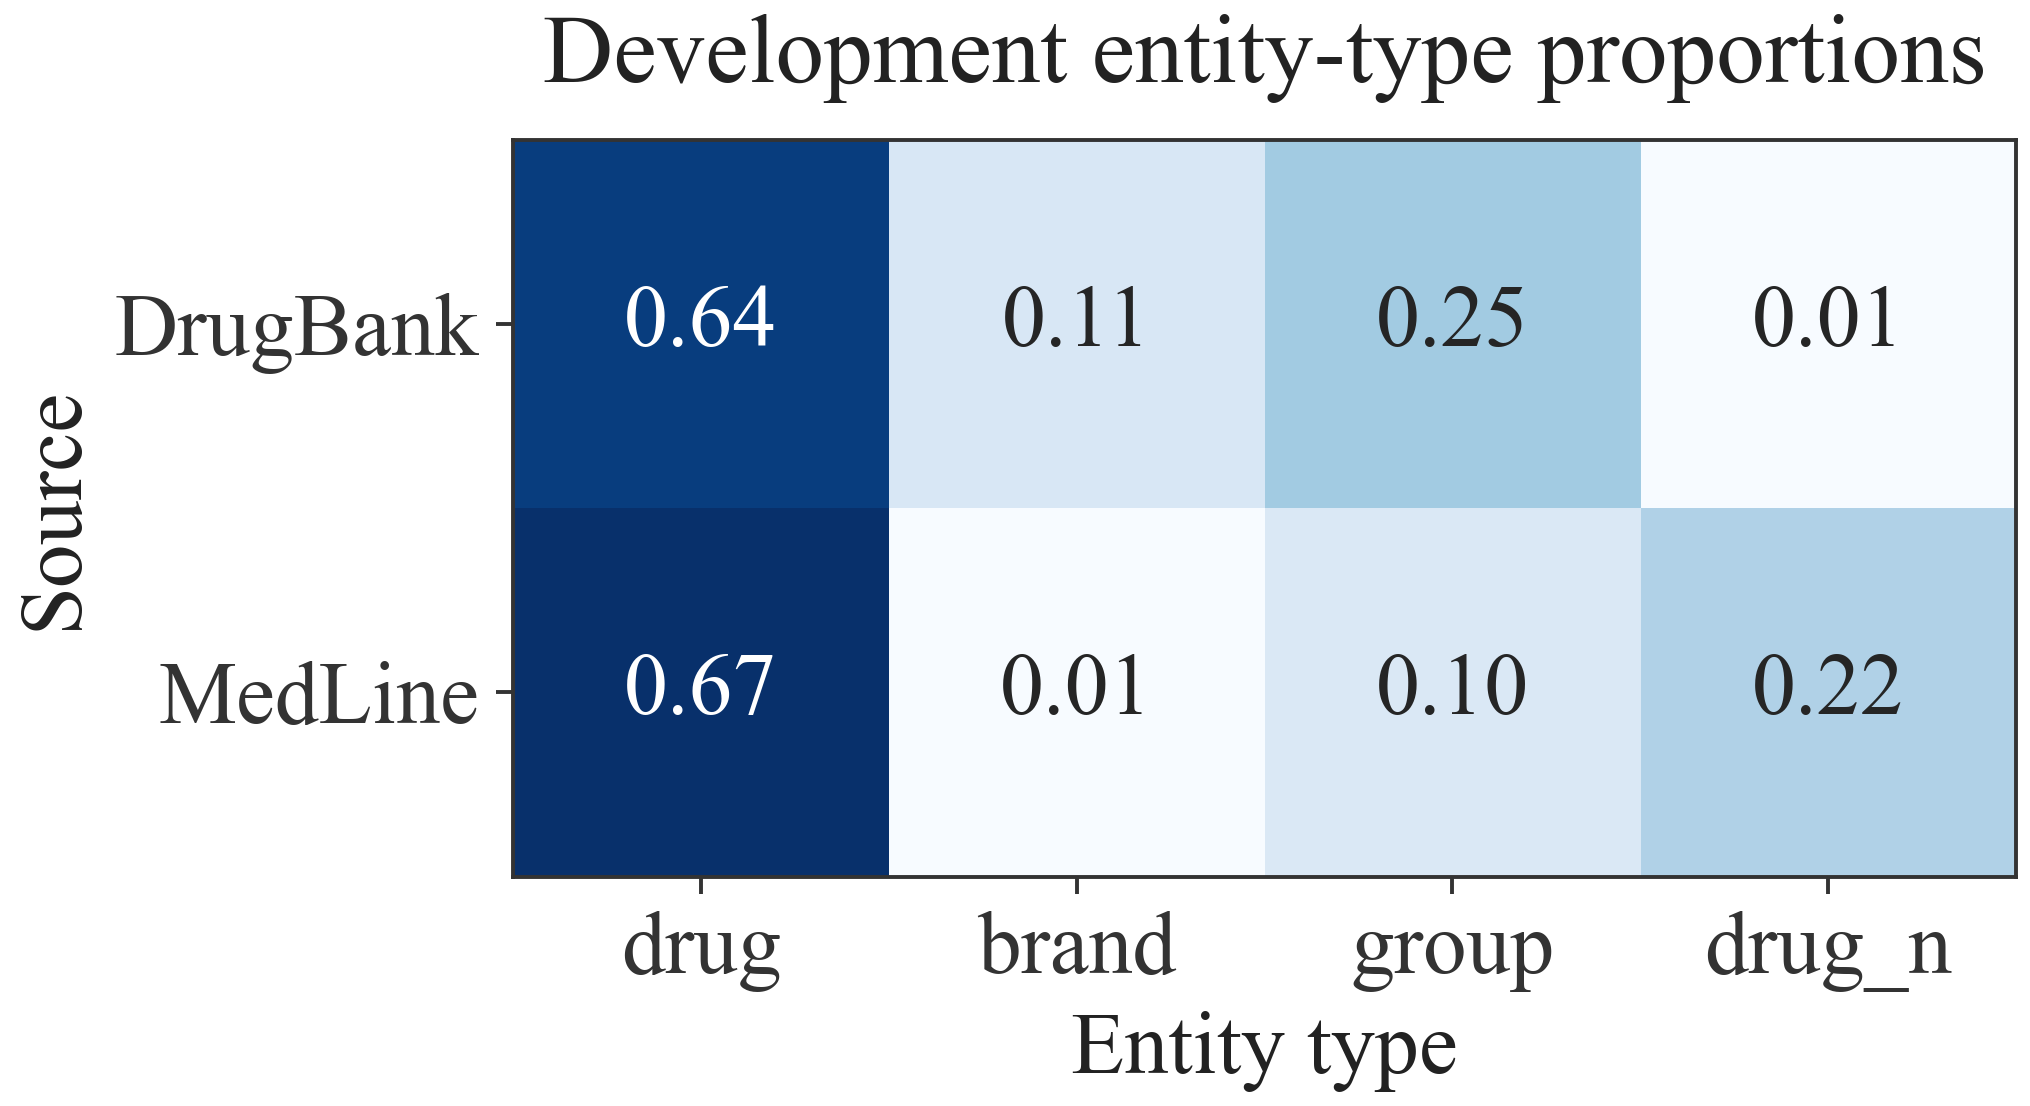

In [20]:
mix = gold.groupby(["source", "entity_type"]).size().rename("Count").reset_index()
mix["Share"] = mix.Count / mix.groupby("source").Count.transform("sum")
plot_data = mix.copy()
assert not plot_data.empty
fig, ax = plt.subplots(figsize=(5.8, 3.16), layout="constrained")
fig.get_layout_engine().set(w_pad=0.04, h_pad=0.04, wspace=0.02, hspace=0.02)
matrix = plot_data.pivot(index="source", columns="entity_type", values="Share")
for axis in ("index", "columns"):
    labels = list(getattr(matrix, axis))
    order = (
        list(ENTITY_TYPES) + ["No exact span"]
        if set(ENTITY_TYPES) <= set(labels)
        else ["O", "B", "I", "E", "S"]
    )
    if set(labels) <= set(order):
        matrix = matrix.reindex(**{axis: [label for label in order if label in labels]})
values = matrix.to_numpy(dtype=float)
finite = values[np.isfinite(values)]
assert not np.isinf(values).any()
signed = bool(len(finite) and finite.min() < 0)
colormap = mpl.colormaps["RdBu_r" if signed else "Blues"].copy()
colormap.set_bad("#E4E4E4")
heatmap = ax.imshow(
    np.ma.masked_invalid(values),
    cmap=colormap,
    aspect="auto",
    **{"vmin": -1, "vmax": 1} if signed else {},
)
short_labels = {
    "Overlong": "Too\nlong",
    "Underlong": "Too\nshort",
    "Shifted overlap": "Shifted",
    "Wrong type": "Wrong\ntype",
}
ax.set_xticks(
    range(len(matrix.columns)),
    [short_labels.get(str(v), textwrap.fill(str(v), 11)) for v in matrix.columns],
)
ax.set_yticks(range(len(matrix)), [textwrap.fill(str(v), 16) for v in matrix.index])
for (row, column), value in np.ndenumerate(values):
    rgba = heatmap.cmap(heatmap.norm(value))
    luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
    if not np.isfinite(value):
        annotation = "N/A"
    elif "Share" == "Count":
        annotation = f"{value:,.0f}"
    elif 0 < abs(value) < 0.005:
        annotation = ">−0.01" if value < 0 else "<0.01"
    else:
        annotation = f"{value:.2f}".replace("-", "−")
    ax.text(
        column,
        row,
        annotation,
        ha="center",
        va="center",
        fontsize=18,
        color="white" if np.isfinite(value) and luminance < 0.5 else INK,
    )
if np.isnan(values).any():
    assert None
    fig.supxlabel(textwrap.fill(None, 52), fontsize=18, color=INK)
ax.set_title("Development entity-type proportions", fontsize=20, pad=12)
ax.set_xlabel("Entity type")
ax.set_ylabel("Source")
fig.set_dpi(350)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        label.set_fontfamily("Times New Roman")
fig.savefig(PROJECT_ROOT / "figures/PNG/pub_01_type_mix.png", dpi=350, facecolor="white")
fig.savefig(PROJECT_ROOT / "figures/PDF/pub_01_type_mix.pdf", dpi=350, facecolor="white")
plot_data.to_csv(
    PROJECT_ROOT / "artifacts/figure_pub_01_type_mix_data.csv", index=False, na_rep="N/A"
)
plt.show()
plt.close(fig)

The four classes are not represented equally in the two sources.

Each source row sums to 1 across drug, brand, group, and drug_n.

Overall scores must be accompanied by class and source analysis.

**Scope.** A heatmap does not test independence between mentions.

## Character-length distribution

**Scientific question.** Does mention length have a heavy right tail?

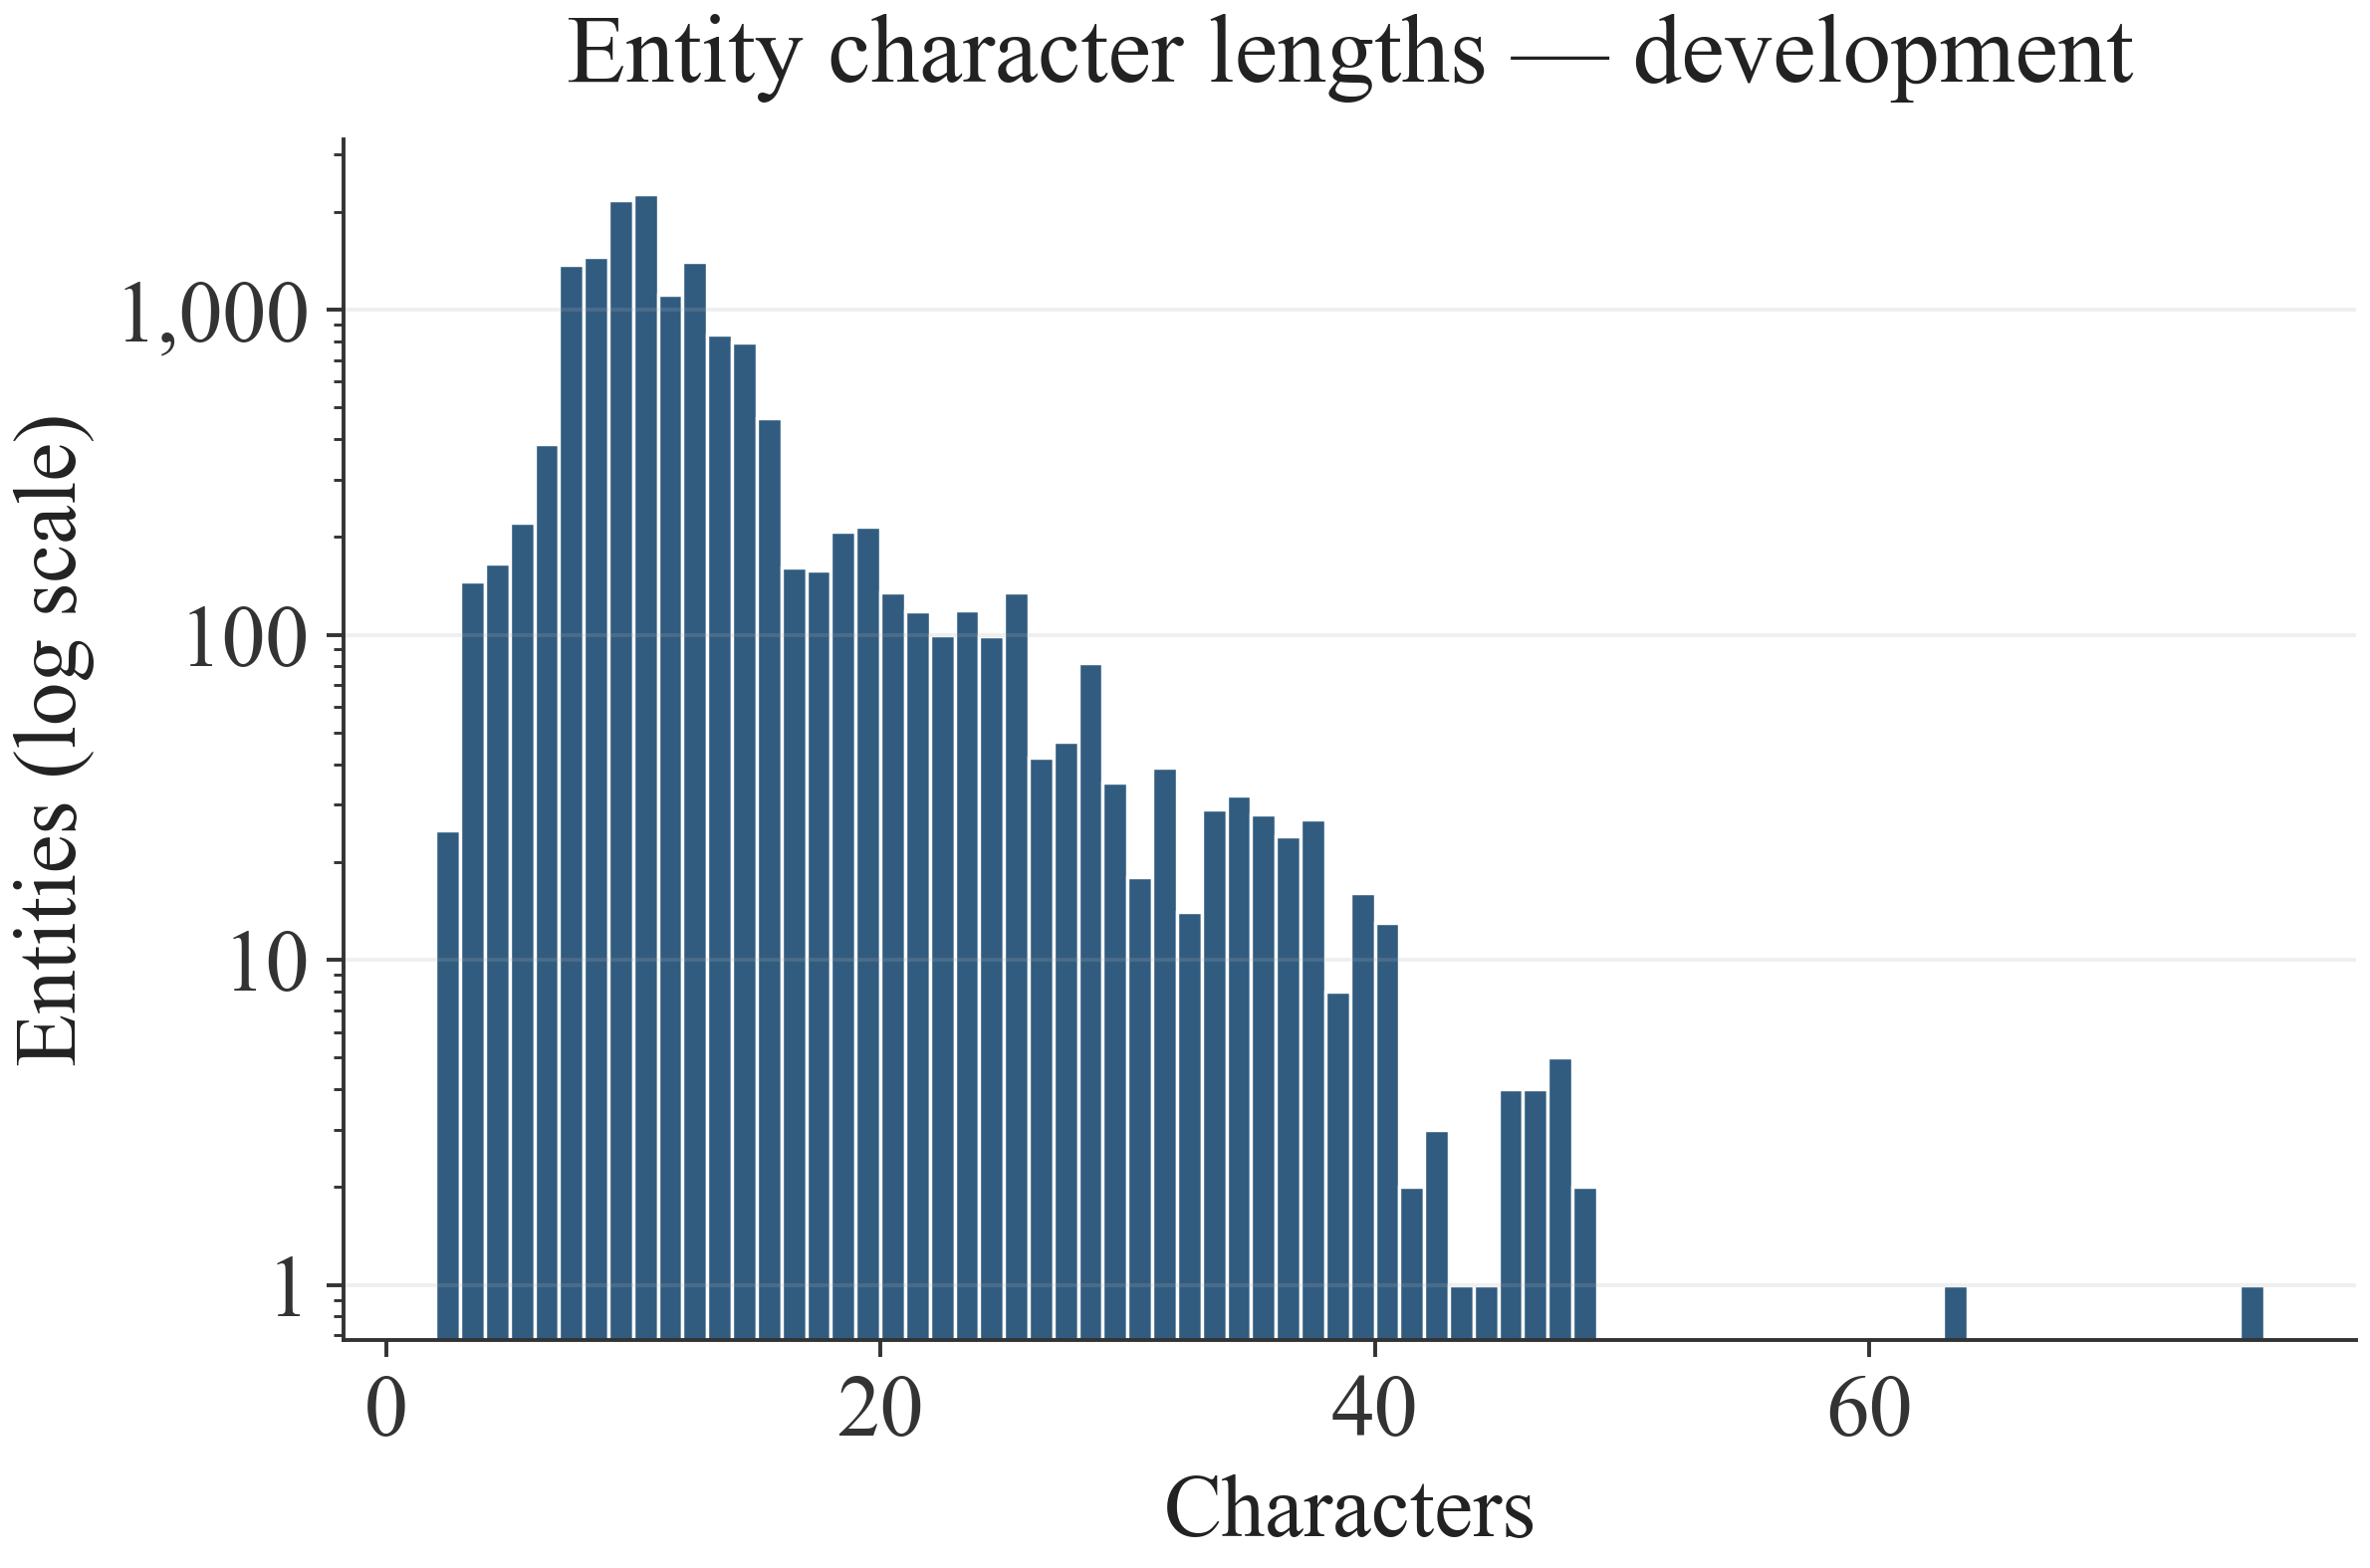

In [21]:
lengths = gold[["Characters"]].copy()
plot_data = lengths.copy()
assert not plot_data.empty
fig, ax = plt.subplots(figsize=(6.8, 4.5), layout="constrained")
fig.get_layout_engine().set(w_pad=0.04, h_pad=0.04, wspace=0.02, hspace=0.02)
ax.hist(plot_data["Characters"], bins="fd", color=BLUE, edgecolor="white", linewidth=0.7)
if plot_data["Characters"].max() > 3 * plot_data["Characters"].quantile(0.75):
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(
        mpl.ticker.FuncFormatter(
            lambda value, position: f"{value:,.0f}" if value >= 1 else f"{value:g}"
        )
    )
ax.set_title("Entity character lengths – development", fontsize=20, pad=12)
ax.set_xlabel("Characters")
ax.set_ylabel("Entities")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
if ax.get_yscale() == "log":
    ax.set_ylabel("Entities (log scale)")
fig.set_dpi(350)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        label.set_fontfamily("Times New Roman")
fig.savefig(
    PROJECT_ROOT / "figures/PNG/pub_01_character_length.png", dpi=350, facecolor="white"
)
fig.savefig(
    PROJECT_ROOT / "figures/PDF/pub_01_character_length.pdf", dpi=350, facecolor="white"
)
plot_data.to_csv(
    PROJECT_ROOT / "artifacts/figure_pub_01_character_length_data.csv", index=False, na_rep="N/A"
)
plt.show()
plt.close(fig)

The full length range is retained; no tail is silently capped.

14727 eligible spans contribute to this distribution.

Long names create different boundary risks from single-token mentions.

**Scope.** Character length is not token length.

## Token-length distribution

**Scientific question.** How common are multi-token pharmacological mentions?

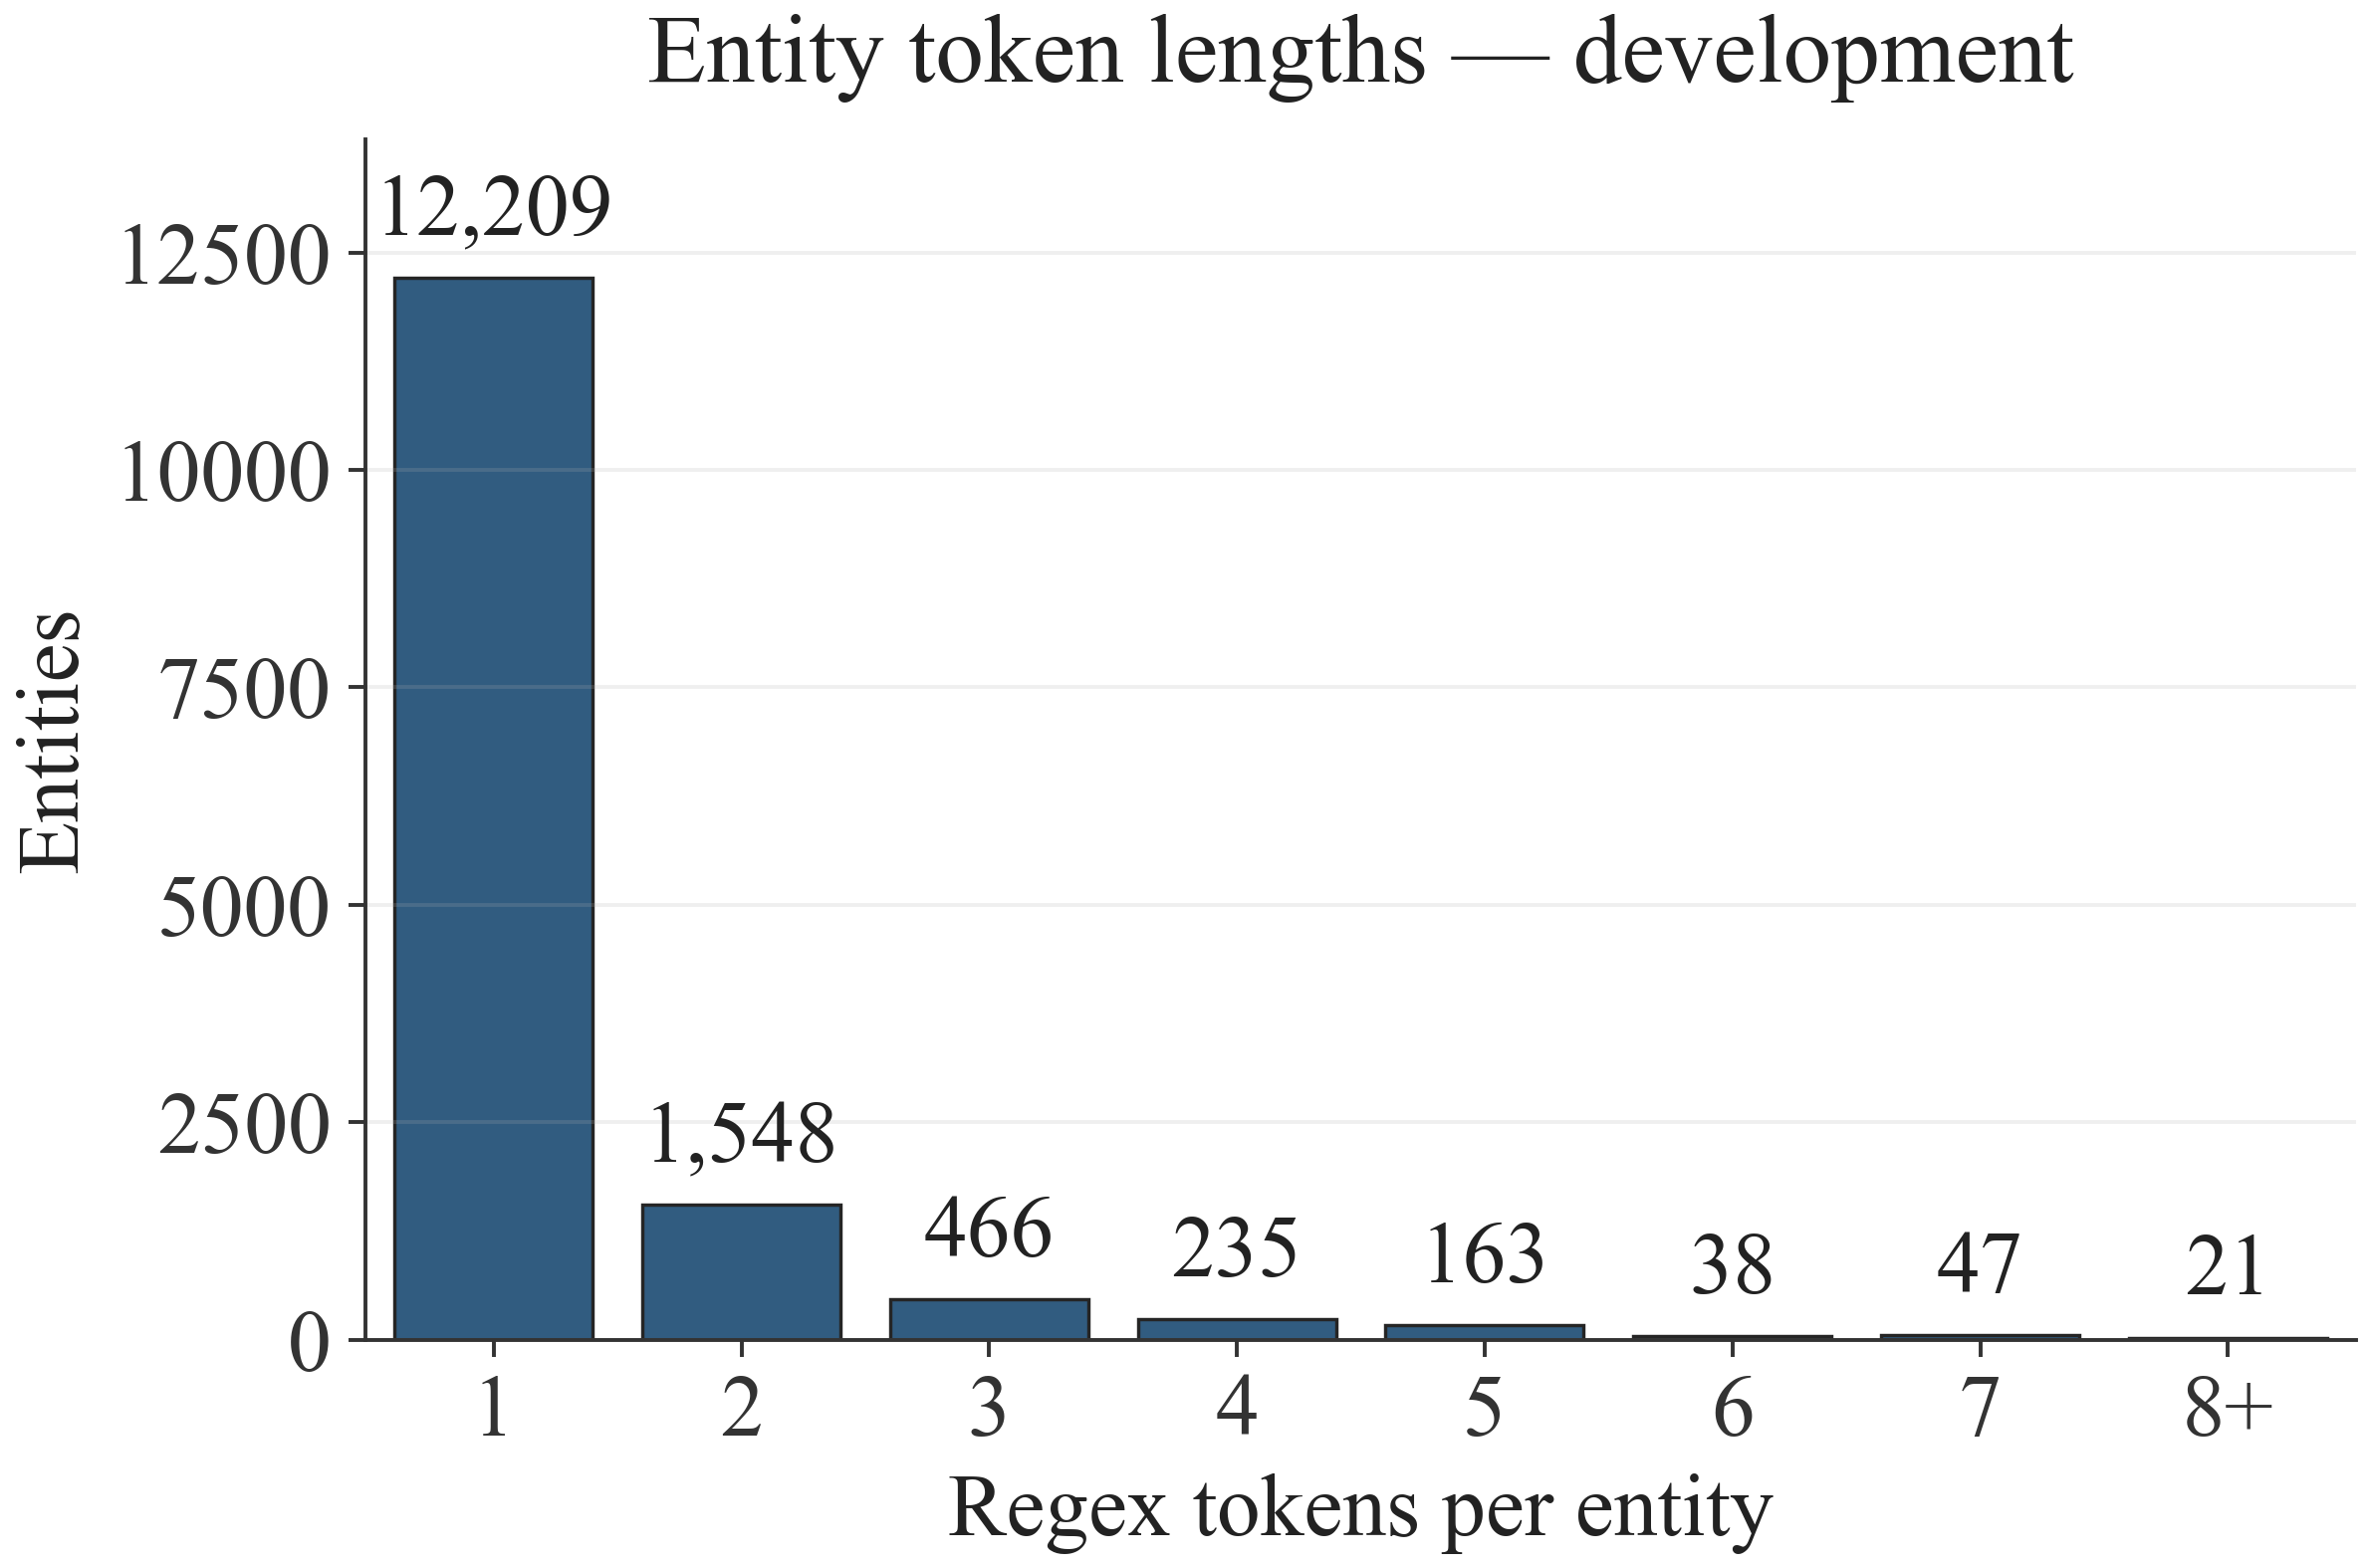

In [22]:
length_counts = (
    gold["Regex tokens"]
    .clip(upper=8)
    .value_counts()
    .sort_index()
    .rename_axis("Tokens")
    .reset_index(name="Entities")
)
length_counts["Tokens"] = length_counts.Tokens.map(lambda v: "8+" if v == 8 else str(v))
plot_data = length_counts.copy()
assert not plot_data.empty
fig, ax = plt.subplots(figsize=(6.8, 4.5), layout="constrained")
fig.get_layout_engine().set(w_pad=0.04, h_pad=0.04, wspace=0.02, hspace=0.02)
positions = np.arange(len(plot_data))
bars = ax.bar(positions, plot_data["Entities"], color=BLUE, edgecolor=INK, linewidth=0.7)
ax.set_xticks(positions, [textwrap.fill(str(v), 21) for v in plot_data["Tokens"]])
ax.margins(y=0.13, x=0.015)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in plot_data["Entities"]], padding=5, fontsize=18)
ax.set_title("Entity token lengths – development", fontsize=20, pad=12)
ax.set_xlabel("Regex tokens per entity")
ax.set_ylabel("Entities")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
fig.set_dpi(350)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        label.set_fontfamily("Times New Roman")
fig.savefig(PROJECT_ROOT / "figures/PNG/pub_01_token_length.png", dpi=350, facecolor="white")
fig.savefig(PROJECT_ROOT / "figures/PDF/pub_01_token_length.pdf", dpi=350, facecolor="white")
plot_data.to_csv(
    PROJECT_ROOT / "artifacts/figure_pub_01_token_length_data.csv", index=False, na_rep="N/A"
)
plt.show()
plt.close(fig)

The upper tail is explicitly pooled into the 8+ category.

2518 of 14727 mentions have more than one regex token.

Pooled tail categories keep labels readable without changing typography.

**Scope.** The primary model tokenization is WordPiece.

## Document-level source association

**Scientific question.** Are source differences larger than random reassignment of document labels?

In [23]:
def holm(values):
    p = np.asarray(values)
    order = np.argsort(p)
    result = np.zeros(len(p))
    result[order] = np.minimum(
        1, np.maximum.accumulate(p[order] * (len(p) - np.arange(len(p))))
    )
    return result

In [24]:
def document_source_tests(profile, permutations=1999):
    rng = np.random.default_rng(1701)
    source = profile.source.eq("DrugBank").to_numpy()
    rows = []
    for feature in ["Mean_sentence_tokens", "Entities", "brand", "drug_n"]:
        values = profile[feature].to_numpy(float)
        if feature in ENTITY_TYPES:
            values = values / np.maximum(profile.Entities, 1)
        observed = values[source].mean() - values[~source].mean()
        null = []
        for _ in range(permutations):
            label = rng.permutation(source)
            null.append(values[label].mean() - values[~label].mean())
        pooled = np.sqrt((values[source].var(ddof=1) + values[~source].var(ddof=1)) / 2)
        rows.append(
            {
                "Feature": feature.replace("_", " "),
                "N Documents": len(profile),
                "DrugBank mean": values[source].mean(),
                "MedLine mean": values[~source].mean(),
                "SMD": observed / pooled if pooled else 0.0,
                "Permutation p": (1 + np.sum(np.abs(null) >= abs(observed)))
                / (permutations + 1),
            }
        )
    frame = pd.DataFrame(rows)
    frame["Holm p"] = holm(frame["Permutation p"])
    return frame

In [25]:
source_tests = document_source_tests(document_profile, permutations=1999)
result_table = source_tests.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_01_document_source_tests.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Feature,N Documents,DrugBank mean,MedLine mean,SMD,Permutation p,Holm p
Mean sentence tokens,714,23.1579,25.0273,−0.1955,0.0745,0.0745
Entities,714,22.5455,12.8944,0.4788,0.0005,0.0020
brand,714,0.1358,0.0101,0.7840,0.0005,0.0020
drug n,714,0.0091,0.1649,−0.7471,0.0005,0.0020


Mean structure and rare-type shares are compared at the document level.

1,999 label permutations; four hypotheses with Holm adjustment.

The SMD quantifies magnitude while adjusted p-values describe sampling evidence.

**Scope.** Exchangeability is an approximation; source is not randomized.

## Structural dependence

**Scientific question.** Which descriptive sentence features carry redundant information?

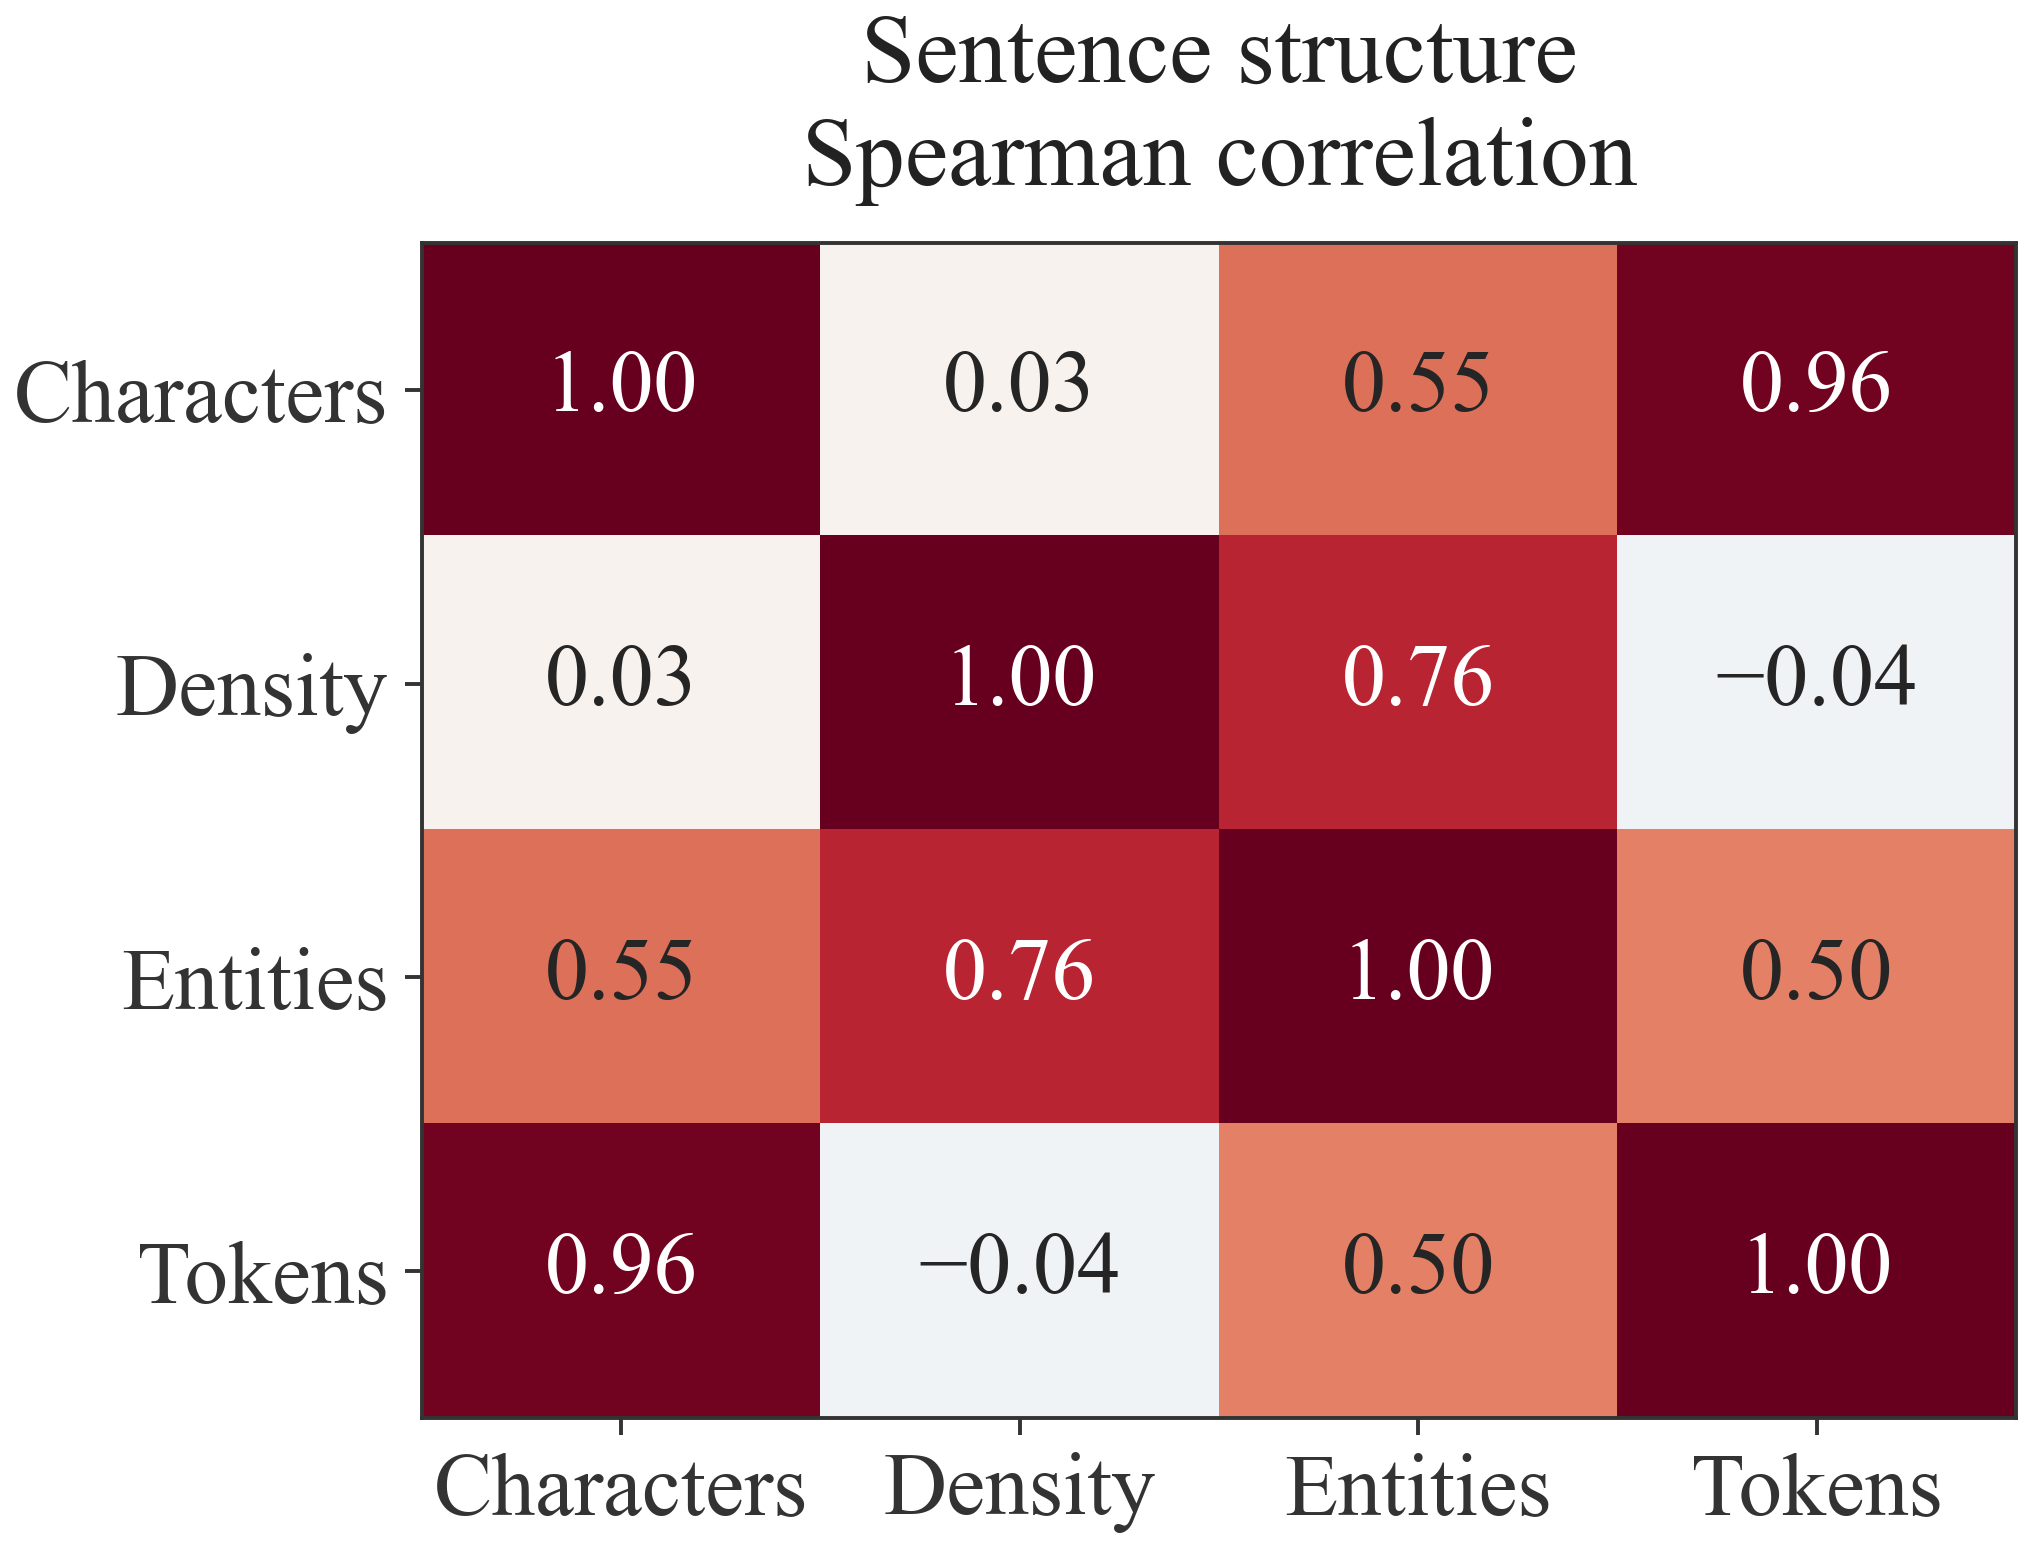

In [26]:
correlation = sentences[["Characters", "Tokens", "Entities", "Density"]].corr(method="spearman")
correlation.index.name = "Feature A"
correlation = correlation.reset_index().melt(
    "Feature A", var_name="Feature B", value_name="Spearman rho"
)
plot_data = correlation.copy()
assert not plot_data.empty
fig, ax = plt.subplots(figsize=(5.8, 4.42), layout="constrained")
fig.get_layout_engine().set(w_pad=0.04, h_pad=0.04, wspace=0.02, hspace=0.02)
matrix = plot_data.pivot(index="Feature A", columns="Feature B", values="Spearman rho")
for axis in ("index", "columns"):
    labels = list(getattr(matrix, axis))
    order = (
        list(ENTITY_TYPES) + ["No exact span"]
        if set(ENTITY_TYPES) <= set(labels)
        else ["O", "B", "I", "E", "S"]
    )
    if set(labels) <= set(order):
        matrix = matrix.reindex(**{axis: [label for label in order if label in labels]})
values = matrix.to_numpy(dtype=float)
finite = values[np.isfinite(values)]
assert not np.isinf(values).any()
signed = bool(len(finite) and finite.min() < 0)
colormap = mpl.colormaps["RdBu_r" if signed else "Blues"].copy()
colormap.set_bad("#E4E4E4")
heatmap = ax.imshow(
    np.ma.masked_invalid(values),
    cmap=colormap,
    aspect="auto",
    **{"vmin": -1, "vmax": 1} if signed else {},
)
short_labels = {
    "Overlong": "Too\nlong",
    "Underlong": "Too\nshort",
    "Shifted overlap": "Shifted",
    "Wrong type": "Wrong\ntype",
}
ax.set_xticks(
    range(len(matrix.columns)),
    [short_labels.get(str(v), textwrap.fill(str(v), 11)) for v in matrix.columns],
)
ax.set_yticks(range(len(matrix)), [textwrap.fill(str(v), 16) for v in matrix.index])
for (row, column), value in np.ndenumerate(values):
    rgba = heatmap.cmap(heatmap.norm(value))
    luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
    if not np.isfinite(value):
        annotation = "N/A"
    elif "Spearman rho" == "Count":
        annotation = f"{value:,.0f}"
    elif 0 < abs(value) < 0.005:
        annotation = ">−0.01" if value < 0 else "<0.01"
    else:
        annotation = f"{value:.2f}".replace("-", "−")
    ax.text(
        column,
        row,
        annotation,
        ha="center",
        va="center",
        fontsize=18,
        color="white" if np.isfinite(value) and luminance < 0.5 else INK,
    )
if np.isnan(values).any():
    assert None
    fig.supxlabel(textwrap.fill(None, 52), fontsize=18, color=INK)
ax.set_title("Sentence structure\nSpearman correlation", fontsize=20, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
fig.set_dpi(350)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        label.set_fontfamily("Times New Roman")
fig.savefig(
    PROJECT_ROOT / "figures/PNG/pub_01_structure_correlation.png", dpi=350, facecolor="white"
)
fig.savefig(
    PROJECT_ROOT / "figures/PDF/pub_01_structure_correlation.pdf", dpi=350, facecolor="white"
)
plot_data.to_csv(
    PROJECT_ROOT / "artifacts/figure_pub_01_structure_correlation_data.csv",
    index=False,
    na_rep="N/A",
)
plt.show()
plt.close(fig)

Character and regex-token lengths carry strongly redundant structural information.

Sentence-level Spearman rho for character length versus token count = 0.9624; four descriptors are shown.

The matrix diagnoses redundancy, not feature importance or causal influence.

**Scope.** Entity density contains the target and must not become an inference feature.

## Surface concentration

**Scientific question.** Is performance exposed to a small vocabulary of repeated mentions?

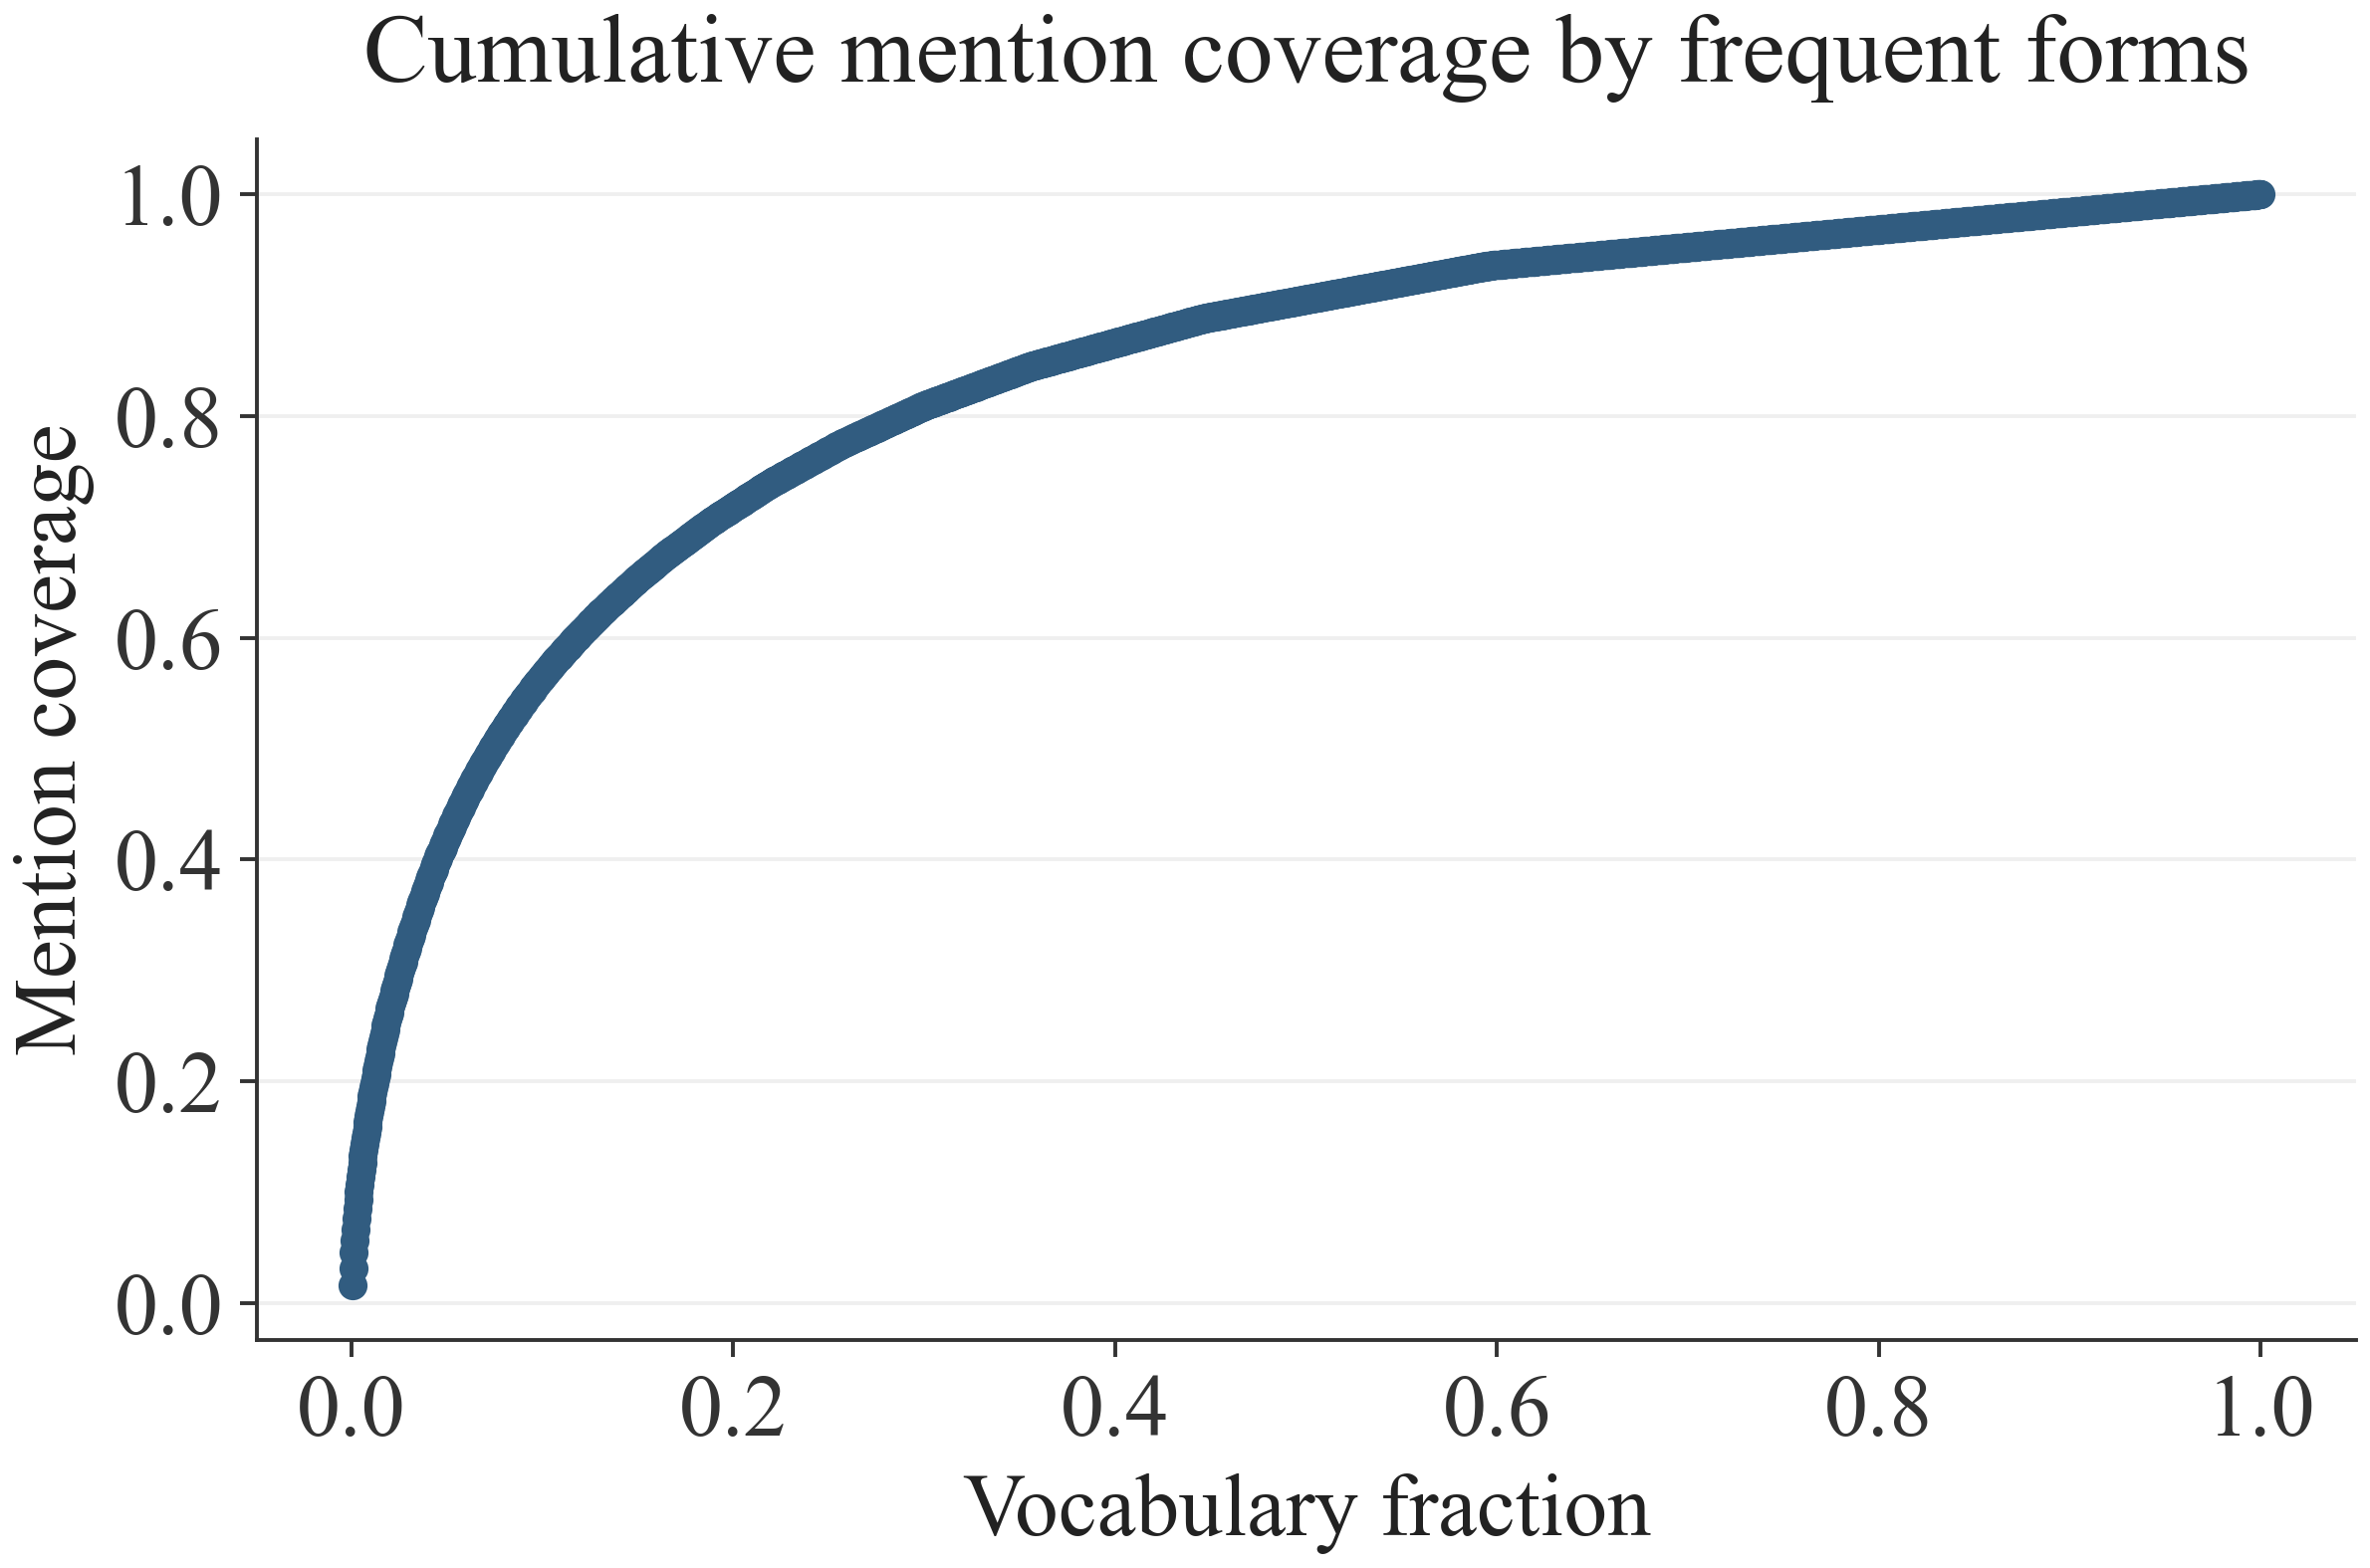

In [27]:
frequency = gold.Normalized.value_counts().rename("Count").reset_index(drop=True).to_frame()
frequency["Vocabulary fraction"] = (np.arange(len(frequency)) + 1) / len(frequency)
frequency["Mention coverage"] = frequency.Count.cumsum() / frequency.Count.sum()
plot_data = frequency.copy()
assert not plot_data.empty
fig, ax = plt.subplots(figsize=(6.8, 4.5), layout="constrained")
fig.get_layout_engine().set(w_pad=0.04, h_pad=0.04, wspace=0.02, hspace=0.02)
groups = [("", plot_data)]
colors = [BLUE, GOLD, "#67713B", "#965F7E", "#777777", "#3B757A", "#A75936"]
for index, (group, points) in enumerate(groups):
    label = textwrap.fill(str(group), 25) if group else None
    ax.plot(
        points["Vocabulary fraction"],
        points["Mention coverage"],
        marker=["o", "s", "^"][index % 3],
        markersize=5,
        linewidth=1.8,
        color=colors[index % len(colors)],
        label=label,
    )
ax.set_title("Cumulative mention coverage by frequent forms", fontsize=20, pad=12)
ax.set_xlabel("Vocabulary fraction")
ax.set_ylabel("Mention coverage")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
fig.set_dpi(350)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        label.set_fontfamily("Times New Roman")
fig.savefig(
    PROJECT_ROOT / "figures/PNG/pub_01_surface_concentration.png", dpi=350, facecolor="white"
)
fig.savefig(
    PROJECT_ROOT / "figures/PDF/pub_01_surface_concentration.pdf", dpi=350, facecolor="white"
)
plot_data.to_csv(
    PROJECT_ROOT / "artifacts/figure_pub_01_surface_concentration_data.csv",
    index=False,
    na_rep="N/A",
)
plt.show()
plt.close(fig)

Surface repetition can make seen-entity performance much easier than unseen performance.

2344 normalized development forms are ordered by frequency.

Coverage is a vocabulary concentration measure, not a train/test leakage proof.

**Scope.** Frequency combines Train and Validation for descriptive analysis only.

## Duplicate-document graph

**Scientific question.** Do exact shared sentence forms connect documents across the development split?

In [28]:
def duplicate_graph(sentences):
    normalized = sentences.text.map(lambda x: re.sub("\\s+", " ", x).strip().casefold())
    f = sentences.assign(normalized=normalized)
    documents = sorted(sentences.document_id.unique())
    ids = {d: i for i, d in enumerate(documents)}
    edges = set()
    cross = 0
    for _, group in f[f.normalized.str.len().ge(40)].groupby("normalized"):
        ds = sorted(group.document_id.unique())
        if len(ds) < 2:
            continue
        if group.split.nunique() > 1:
            cross += 1
        edges.update(((ids[ds[0]], ids[d]) for d in ds[1:]))
    rr = [i for edge in edges for i in edge]
    cc = [i for edge in edges for i in edge[::-1]]
    adjacency = coo_matrix((np.ones(len(rr)), (rr, cc)), shape=(len(documents), len(documents)))
    ncomp, labels = connected_components(adjacency, directed=False)
    sizes = pd.Series(labels).value_counts()
    return pd.DataFrame(
        [
            {
                "Documents": len(documents),
                "Components": ncomp,
                "Nontrivial components": int((sizes > 1).sum()),
                "Largest component": int(sizes.max()),
                "Shared sentence forms across splits": cross,
                "Minimum normalized characters": 40,
            }
        ]
    )

In [29]:
duplicate_components = duplicate_graph(sentences)
result_table = duplicate_components.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_01_duplicate_graph.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 0)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Documents,Components,Nontrivial components,Largest component,Shared sentence forms across splits,Minimum normalized characters
714,660,31,10,38,40


Shared substantial sentence forms define a document-dependence graph.

38 normalized forms cross Train/Validation; largest component: 10 documents.

Connected components identify dependence that document-ID disjointness alone cannot remove.

**Scope.** Only exact normalized forms of at least 40 characters are linked; no semantic duplicate detection is claimed.

## Training co-mention graph

**Scientific question.** Which entity types co-occur in training sentences?

In [30]:
def cooccurrence_graph(sentences, gold):
    presence = (
        pd.crosstab(gold.sentence_id, gold.entity_type)
        .reindex(index=sentences.sentence_id, columns=ENTITY_TYPES, fill_value=0)
        .gt(0)
    )
    rows = []
    for a, b in combinations(ENTITY_TYPES, 2):
        both = int((presence[a] & presence[b]).sum())
        union = int((presence[a] | presence[b]).sum())
        rows.append(
            {
                "Type A": a,
                "Type B": b,
                "Co-mention sentences": both,
                "Union sentences": union,
                "Jaccard": both / union if union else 0.0,
                "Scope": "Train only; undirected co-mention",
            }
        )
    return pd.DataFrame(rows)

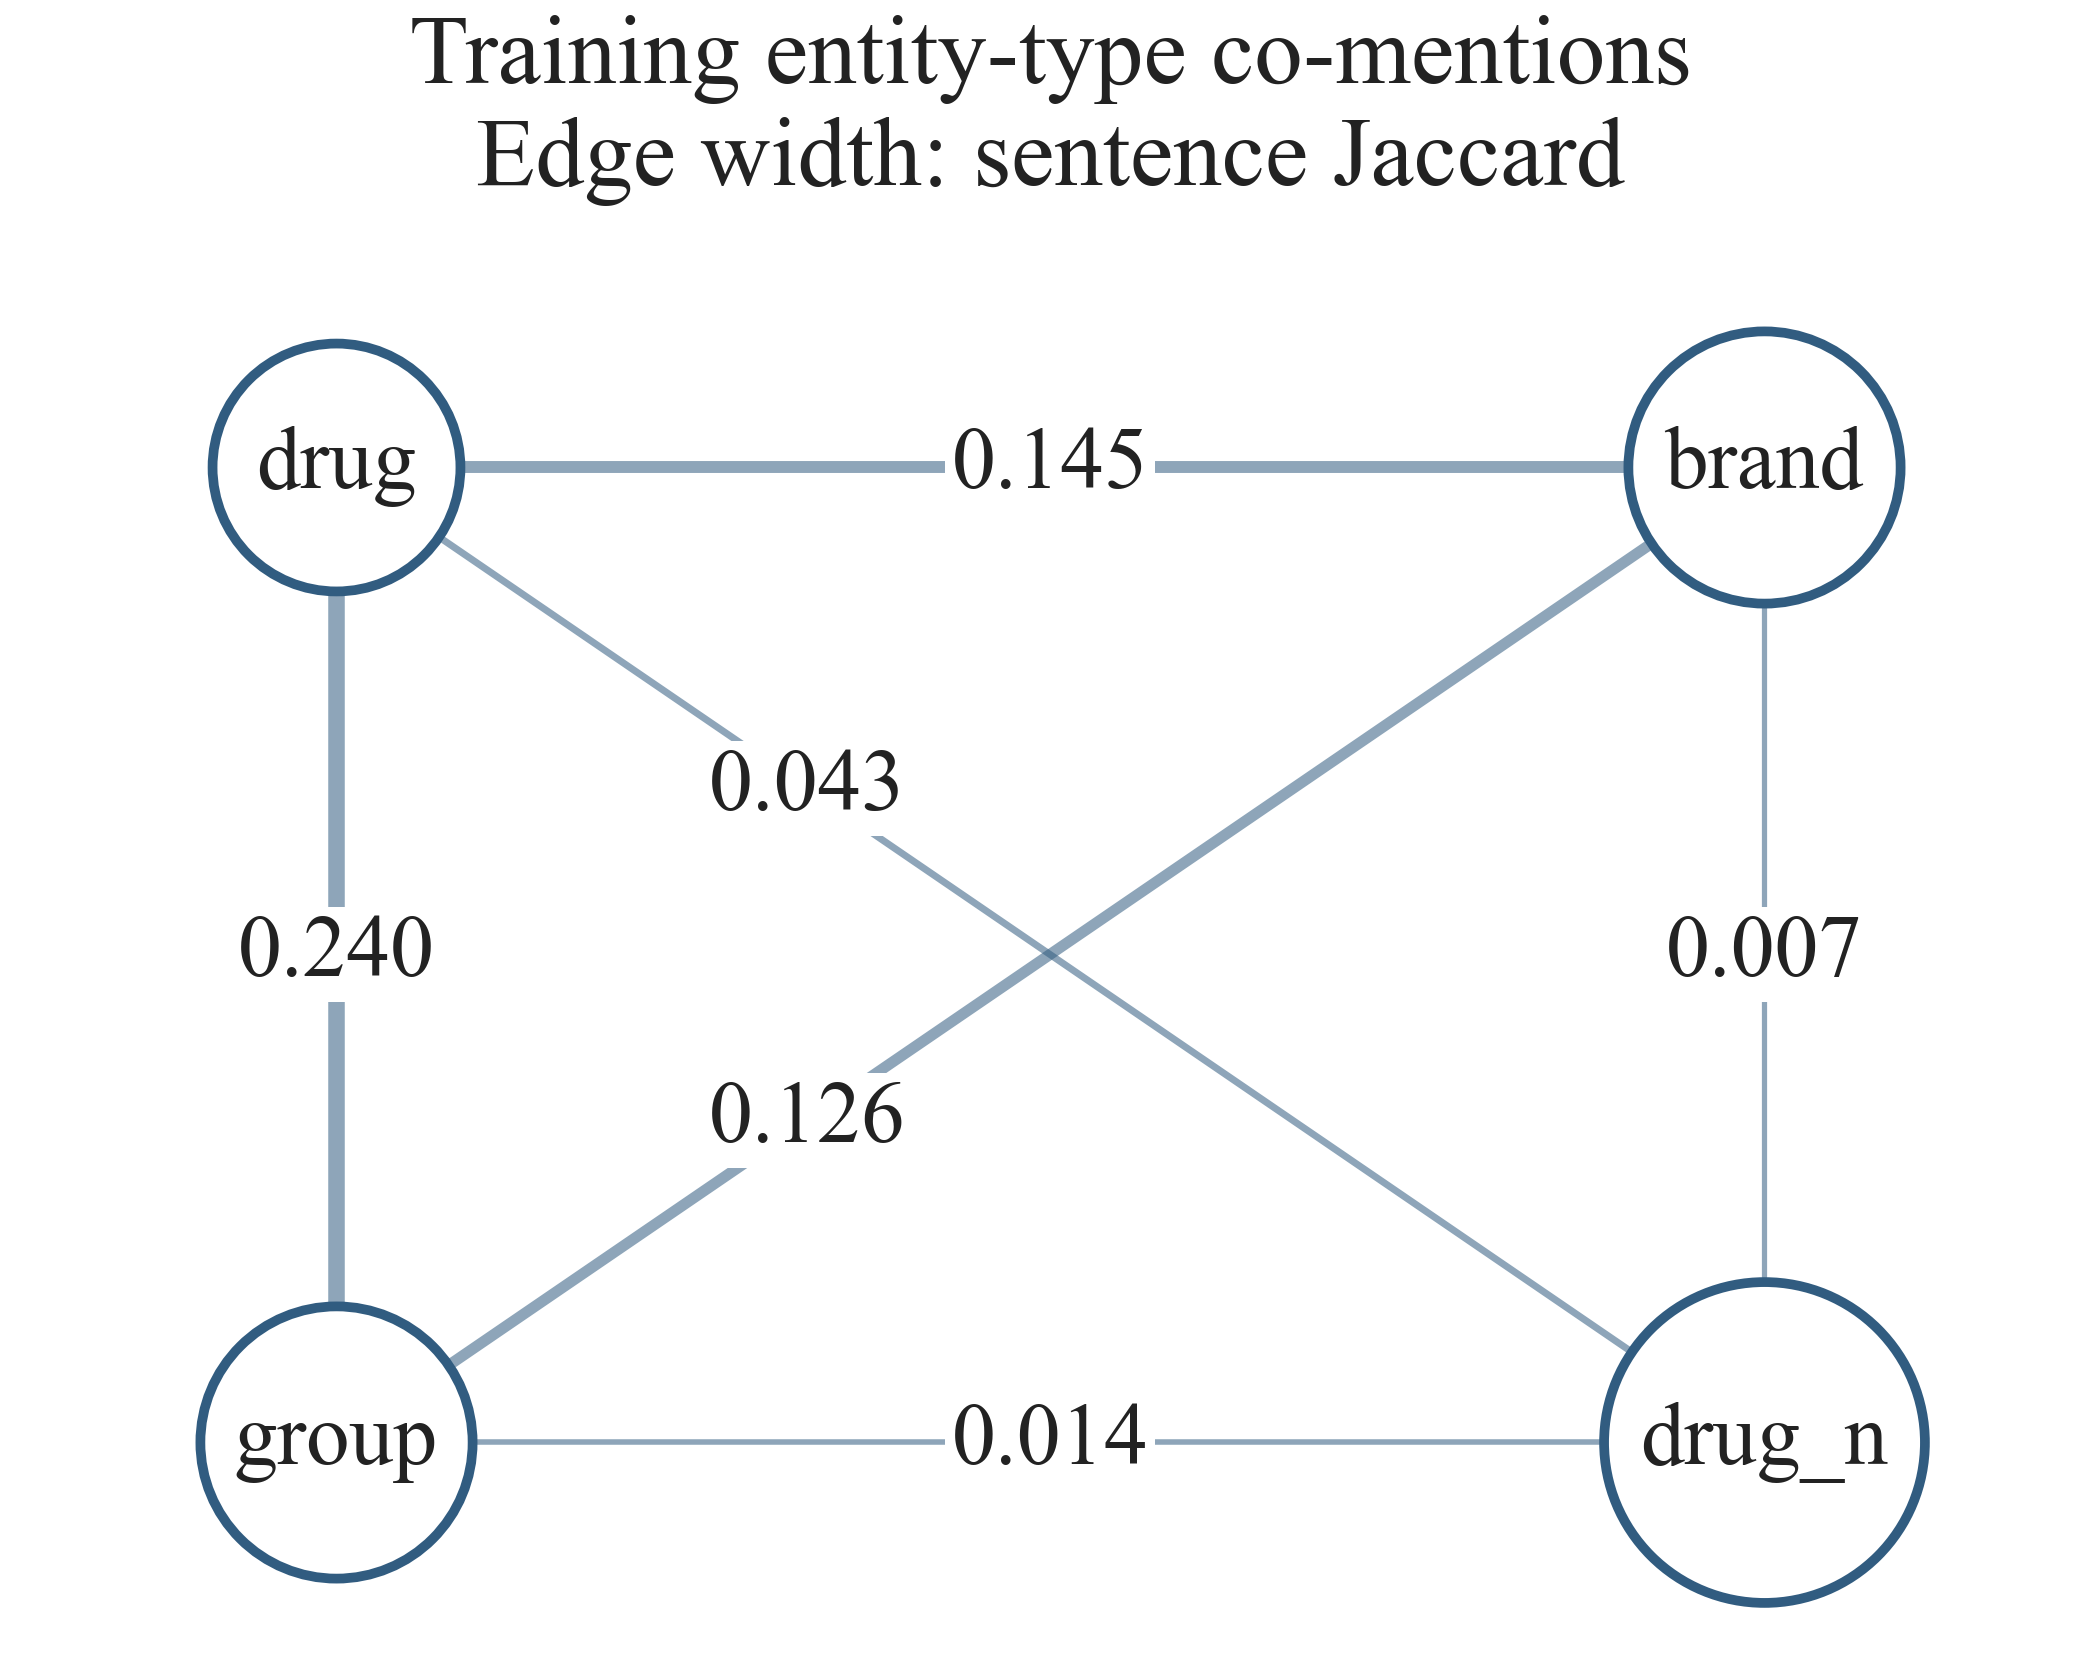

In [31]:
train_sentences = sentences.loc[sentences.split.eq("train")]
train_gold = gold.loc[gold.split.eq("train")]
edges = cooccurrence_graph(train_sentences, train_gold)
edges = edges
fig, ax = plt.subplots(figsize=(6.0, 4.8), layout="constrained")
positions = {
    "drug": (-0.8, 0.7),
    "brand": (0.8, 0.7),
    "group": (-0.8, -0.7),
    "drug_n": (0.8, -0.7),
}
for i, row in edges.iterrows():
    a, b = (positions[row["Type A"]], positions[row["Type B"]])
    ax.plot(
        [a[0], b[0]],
        [a[1], b[1]],
        color=BLUE,
        alpha=0.55,
        linewidth=1 + 10 * row.Jaccard,
        zorder=1,
    )
    fraction = 0.33 if i == 2 else 0.67 if i == 3 else 0.5
    x = a[0] + fraction * (b[0] - a[0])
    y = a[1] + fraction * (b[1] - a[1])
    ax.text(
        x,
        y,
        f"{row.Jaccard:.3f}",
        ha="center",
        va="center",
        fontsize=18,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5},
        zorder=3,
    )
for node, (x, y) in positions.items():
    ax.scatter(
        [x],
        [y],
        s=max(2600, (10 * len(node) + 6) ** 2),
        c="white",
        edgecolors=BLUE,
        linewidths=2,
        zorder=2,
    )
    ax.text(x, y, node, ha="center", va="center", fontsize=18, zorder=3)
ax.set(xlim=(-1.16, 1.16), ylim=(-1.02, 1.02))
ax.axis("off")
ax.set_title(
    "Training entity-type co-mentions\nEdge width: sentence Jaccard", fontsize=20, pad=12
)
fig.set_dpi(350)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        label.set_fontfamily("Times New Roman")
fig.savefig(
    PROJECT_ROOT / "figures/PNG/pub_01_type_comention_graph.png", dpi=350, facecolor="white"
)
fig.savefig(
    PROJECT_ROOT / "figures/PDF/pub_01_type_comention_graph.pdf", dpi=350, facecolor="white"
)
edges.to_csv(
    PROJECT_ROOT / "artifacts/figure_pub_01_type_comention_graph_data.csv",
    index=False,
    na_rep="N/A",
)
plt.show()
plt.close(fig)

The graph encodes shared sentence context across pharmacological types.

Four nodes and six possible undirected edges; widths encode Jaccard similarity.

This is a compact description of annotation context relevant to the linked relation-extraction study.

**Scope.** Co-mention does not establish a drug interaction, causation, or biological relation.

## Corpus concordance

**Scientific question.** What do real pharmacological mentions look like in their original context?

In [32]:
def kwic_examples(sentences, gold, window=32):
    texts = sentences.set_index("sentence_id").text.to_dict()
    rows = []
    for (source, kind), part in gold.query("split == 'train'").groupby(
        ["source", "entity_type"]
    ):
        part = part.assign(
            distance=(part.entity_text.str.len() - part.entity_text.str.len().median()).abs()
        )
        row = part.sort_values(["distance", "entity_id"]).iloc[0]
        text = texts[row.sentence_id]
        rows.append(
            {
                "Source": source,
                "Type": kind,
                "Left context": text[max(0, row.char_start - window) : row.char_start],
                "Entity": row.entity_text,
                "Right context": text[row.char_end : row.char_end + window],
            }
        )
    return pd.DataFrame(rows)

In [33]:
examples = kwic_examples(sentences, gold, window=32)
result_table = examples.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(PROJECT_ROOT / "artifacts/pub_01_kwic_examples.csv", index=False, na_rep="N/A")
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Source,Type,Left context,Entity,Right context
DrugBank,brand,patients understand how to use,FORADIL,(formoterol fumarate) capsules
DrugBank,drug,indicate that administration of,disulfiram,or diazepam does not affect the
DrugBank,drug_n,PEGASYS contains,benzyl alcohol,.
DrugBank,group,"ot been done, it was noted that",corticosteroid,or ACTH treatment of relapses f
MedLine,brand,Quetiapine fumarate (',Seroquel,') is a newly introduced atypica
MedLine,drug,teady-state pharmacokinetics of,quetiapine,.
MedLine,drug_n,"c solutions containing ethanol,",methanol,", higher alcohols and acetaldehy"
MedLine,group,mmunosuppressive drugs in turn (,corticosteroids,", cyclosporin, azathioprine, met"


The concordance exposes the observed text and the four-way target annotation, not synthetic examples.

One Train mention per source/type; at most 32 original characters on each side.

Context is needed to distinguish surface identity from pharmacological subtype.

**Scope.** Examples are selected near the subgroup median entity length for legibility, not to represent all errors.

## Conditional annotation ambiguity

**Scientific question.** How often does one normalized surface receive more than one subtype?

In [34]:
def ambiguity_analysis(gold):
    f = gold.assign(Surface=gold.entity_text.map(normalize_surface))
    rows = []
    details = []
    for (split, source), part in f.groupby(["split", "source"]):
        count = pd.crosstab(part.Surface, part.entity_type)
        n = count.sum(axis=1)
        ambiguous = (count > 0).sum(axis=1) > 1
        h = count.apply(lambda r: entropy(r[r > 0], base=2), axis=1)
        rows.append(
            {
                "Split": split,
                "Source": source,
                "Mentions": len(part),
                "Forms": len(count),
                "Ambiguous forms": int(ambiguous.sum()),
                "Ambiguous mention share": n[ambiguous].sum() / n.sum(),
                "Conditional type entropy (bits)": np.average(h, weights=n),
            }
        )
        for surface in count.index[ambiguous]:
            details.append(
                {
                    "Split": split,
                    "Source": source,
                    "Surface": surface,
                    "Mentions": int(n[surface]),
                    "Type entropy (bits)": h[surface],
                    "Type counts": "; ".join(
                        (f"{k}: {int(v)}" for k, v in count.loc[surface].items() if v)
                    ),
                }
            )
    return (pd.DataFrame(rows), pd.DataFrame(details))

In [35]:
ambiguity, ambiguous_forms = ambiguity_analysis(gold)
result_table = ambiguity.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(PROJECT_ROOT / "artifacts/pub_01_ambiguity.csv", index=False, na_rep="N/A")
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Split,Source,Mentions,Forms,Ambiguous forms,Ambiguous mention share,Conditional type entropy (bits)
train,DrugBank,10352,1821,48,0.0873,0.0296
train,MedLine,1460,410,3,0.0075,0.0061
validation,DrugBank,2544,701,12,0.0228,0.0169
validation,MedLine,371,101,1,0.0081,0.0074


Context-free typing faces measurable surface ambiguity, particularly in DrugBank.

Train DrugBank: 48 ambiguous forms covering 8.73% of mentions; MedLine: 3 forms and 0.75%.

Nonzero conditional entropy limits context-free lexical typing.

**Scope.** Multiple labels can reflect valid contextual ambiguity rather than annotation error.

## Lexical register and diversity

**Scientific question.** Do the two sources differ in vocabulary concentration and contextual variety?

In [36]:
def lexical_register(sentences):
    rows = []
    for (split, source), part in sentences.groupby(["split", "source"]):
        streams = [
            re.findall("\\b[\\w]+(?:[-'][\\w]+)*\\b", text.casefold()) for text in part.text
        ]
        c = Counter((t for stream in streams for t in stream))
        n = sum(c.values())
        windows = []
        for stream in streams:
            for start in range(max(0, len(stream) - 49)):
                windows.append(len(set(stream[start : start + 50])) / 50)
        rows.append(
            {
                "Split": split,
                "Source": source,
                "Word tokens": n,
                "Word types": len(c),
                "Hapax type share": sum((v == 1 for v in c.values())) / len(c),
                "Word entropy (bits)": entropy(list(c.values()), base=2),
                "Mean moving TTR (50 words)": np.mean(windows) if windows else np.nan,
            }
        )
    return pd.DataFrame(rows)

In [37]:
register = lexical_register(sentences)
result_table = register.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_01_lexical_register.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Split,Source,Word tokens,Word types,Hapax type share,Word entropy (bits),Mean moving TTR (50 words)
train,DrugBank,82867,5724,0.4020,9.4318,0.7667
train,MedLine,21493,3971,0.4815,9.6365,0.7556
validation,DrugBank,20619,2781,0.4462,9.1772,0.7506
validation,MedLine,4920,1396,0.5516,8.8589,0.6367


The Train MedLine word vocabulary has a higher hapax share than DrugBank.

Hapax shares: MedLine 48.15%, DrugBank 40.20%; empirical word entropy 9.637 versus 9.432 bits.

Fixed-window TTR reduces the direct dependence of ordinary TTR on total corpus length.

**Scope.** Only sentences with at least 50 words contribute to this TTR; the conditional scope is not the whole corpus.

## Co-mention graph uncertainty

**Scientific question.** Are graph edges stronger than a document-preserving random-label reference?

In [38]:
def comention_inference(sentences, gold, permutations=499, resamples=999):
    sentences = sentences.query("split == 'train'")
    gold = gold.query("split == 'train'")
    types = list(ENTITY_TYPES)
    pairs = list(combinations(range(4), 2))
    codes = {k: i for i, k in enumerate(types)}
    document_data = []
    counts = []

    def summarize(bits):
        present = [bits & 1 << i > 0 for i in range(4)]
        return np.array(
            [
                [np.sum(present[a] & present[b]), np.sum(present[a] | present[b])]
                for a, b in pairs
            ]
        )

    for document, ss in sentences.groupby("document_id"):
        gg = gold[gold.document_id.eq(document)]
        index = {s: i for i, s in enumerate(ss.sentence_id)}
        local = np.array([index[s] for s in gg.sentence_id], dtype=int)
        labels = np.array([codes[t] for t in gg.entity_type], dtype=np.uint8)
        bits = np.zeros(len(ss), dtype=np.uint8)
        np.bitwise_or.at(bits, local, 1 << labels)
        counts.append(summarize(bits))
        document_data.append((len(ss), local, labels))
    counts = np.array(counts)
    observed_counts = counts.sum(axis=0)
    observed = observed_counts[:, 0] / np.maximum(observed_counts[:, 1], 1)
    rng = np.random.default_rng(20260905)
    null = []
    for _ in range(permutations):
        total = np.zeros((6, 2))
        for n, local, labels in document_data:
            bits = np.zeros(n, dtype=np.uint8)
            np.bitwise_or.at(bits, local, 1 << rng.permutation(labels))
            total += summarize(bits)
        null.append(total[:, 0] / np.maximum(total[:, 1], 1))
    null = np.array(null)
    nullmean = null.mean(0)
    p = (1 + np.sum(np.abs(null - nullmean) >= np.abs(observed - nullmean), axis=0)) / (
        permutations + 1
    )
    boot = []
    for _ in range(resamples):
        total = counts[rng.integers(0, len(counts), len(counts))].sum(0)
        boot.append(total[:, 0] / np.maximum(total[:, 1], 1))
    boot = np.array(boot)
    return pd.DataFrame(
        {
            "Type pair": [f"{types[a]} – {types[b]}" for a, b in pairs],
            "Jaccard CI Low": np.quantile(boot, 0.025, axis=0),
            "Jaccard CI High": np.quantile(boot, 0.975, axis=0),
            "Excess over within-document null": observed - nullmean,
            "Randomization p": p,
            "Holm p": holm(p),
        }
    )

In [39]:
graph_evidence = comention_inference(sentences, gold, permutations=499, resamples=999)
result_table = graph_evidence.copy()
assert not result_table.empty
assert (
    not result_table.select_dtypes(include="object")
    .map(lambda value: isinstance(value, str) and (not value.strip()))
    .any()
    .any()
)
result_table.to_csv(
    PROJECT_ROOT / "artifacts/pub_01_graph_inference.csv", index=False, na_rep="N/A"
)
formatters = {
    column: lambda value: format_number(value, 4)
    for column in result_table.select_dtypes(include="floating")
}
result_view = result_table.style.hide(axis="index").format(formatters, na_rep="N/A")
if result_table.isna().any().any():
    assert "Accepted N" in result_table
    assert result_table.loc[result_table.isna().any(axis=1), "Accepted N"].eq(0).all()
    result_view = result_view.set_caption(
        "N/A: confidence metrics are not estimable when Accepted N = 0 (no emitted entities)."
    )
    result_view = result_view.set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "bottom"),
                    ("text-align", "left"),
                    ("padding-top", "0.4em"),
                ],
            }
        ]
    )
if (
    "Model" in result_table
    and result_table.Model.nunique() > 1
    and ("Subgroup" not in result_table)
):
    higher = [
        c
        for c in result_table
        if c
        in (
            "Boundary P",
            "Boundary R",
            "Boundary F1",
            "Typed P",
            "Typed R",
            "Typed F1",
            "Macro-F1",
            "drug F1",
            "brand F1",
            "group F1",
            "drug_n F1",
        )
    ]
    lower = [c for c in result_table if c in ("ECE", "Brier", "Discrete AURC")]
    if higher:
        result_view = result_view.highlight_max(subset=higher, props="font-weight: bold;")
    if lower:
        result_view = result_view.highlight_min(subset=lower, props="font-weight: bold;")
display(result_view)

Type pair,Jaccard CI Low,Jaccard CI High,Excess over within-document null,Randomization p,Holm p
drug – brand,0.1186,0.1694,0.0011,0.7200,0.7200
drug – group,0.2173,0.2625,−0.0463,0.0020,0.0120
drug – drug_n,0.0316,0.0557,0.0061,0.0020,0.0120
brand – group,0.1085,0.1462,−0.0050,0.3280,0.6560
brand – drug_n,0.0024,0.0132,−0.0069,0.0100,0.0300
group – drug_n,0.0077,0.0211,−0.0066,0.0060,0.0240


4 of six co-mention pairs differ from the document-preserving reference at Holm-adjusted 0.05.

Largest absolute excess: drug – group, -0.0463; Holm p = 0.012. Intervals use 999 document draws; p-values use 499 permutations.

Shuffling preserves document type totals and each sentence mention count, isolating sentence-level association beyond those constraints.

**Scope.** This conditional null is descriptive and does not model biological causation; finite-permutation p-values have limited resolution.

## Type-conditioned contexts

**Scientific question.** Are entity types embedded in distinguishable surrounding lexical contexts?

In [40]:
def contextual_type_similarity(sentences, gold, window=6):
    texts = sentences.set_index("sentence_id").text.to_dict()
    contexts = []
    labels = []
    for r in gold.query("split == 'train'").itertuples():
        text = texts[r.sentence_id]
        left = re.findall("\\b\\w+\\b", text[: r.char_start].casefold())[-window:]
        right = re.findall("\\b\\w+\\b", text[r.char_end :].casefold())[:window]
        contexts.append(" ".join(left + right))
        labels.append(r.entity_type)
    vectorizer = TfidfVectorizer(min_df=3, max_features=10000, sublinear_tf=True)
    x = vectorizer.fit_transform(contexts)
    labels = np.array(labels)
    centroids = np.vstack(
        [np.asarray(x[labels == k].mean(axis=0)).ravel() for k in ENTITY_TYPES]
    )
    matrix = cosine_similarity(centroids)
    return (
        pd.DataFrame(matrix, index=ENTITY_TYPES, columns=ENTITY_TYPES)
        .rename_axis("Type A")
        .reset_index()
        .melt("Type A", var_name="Type B", value_name="Cosine")
    )

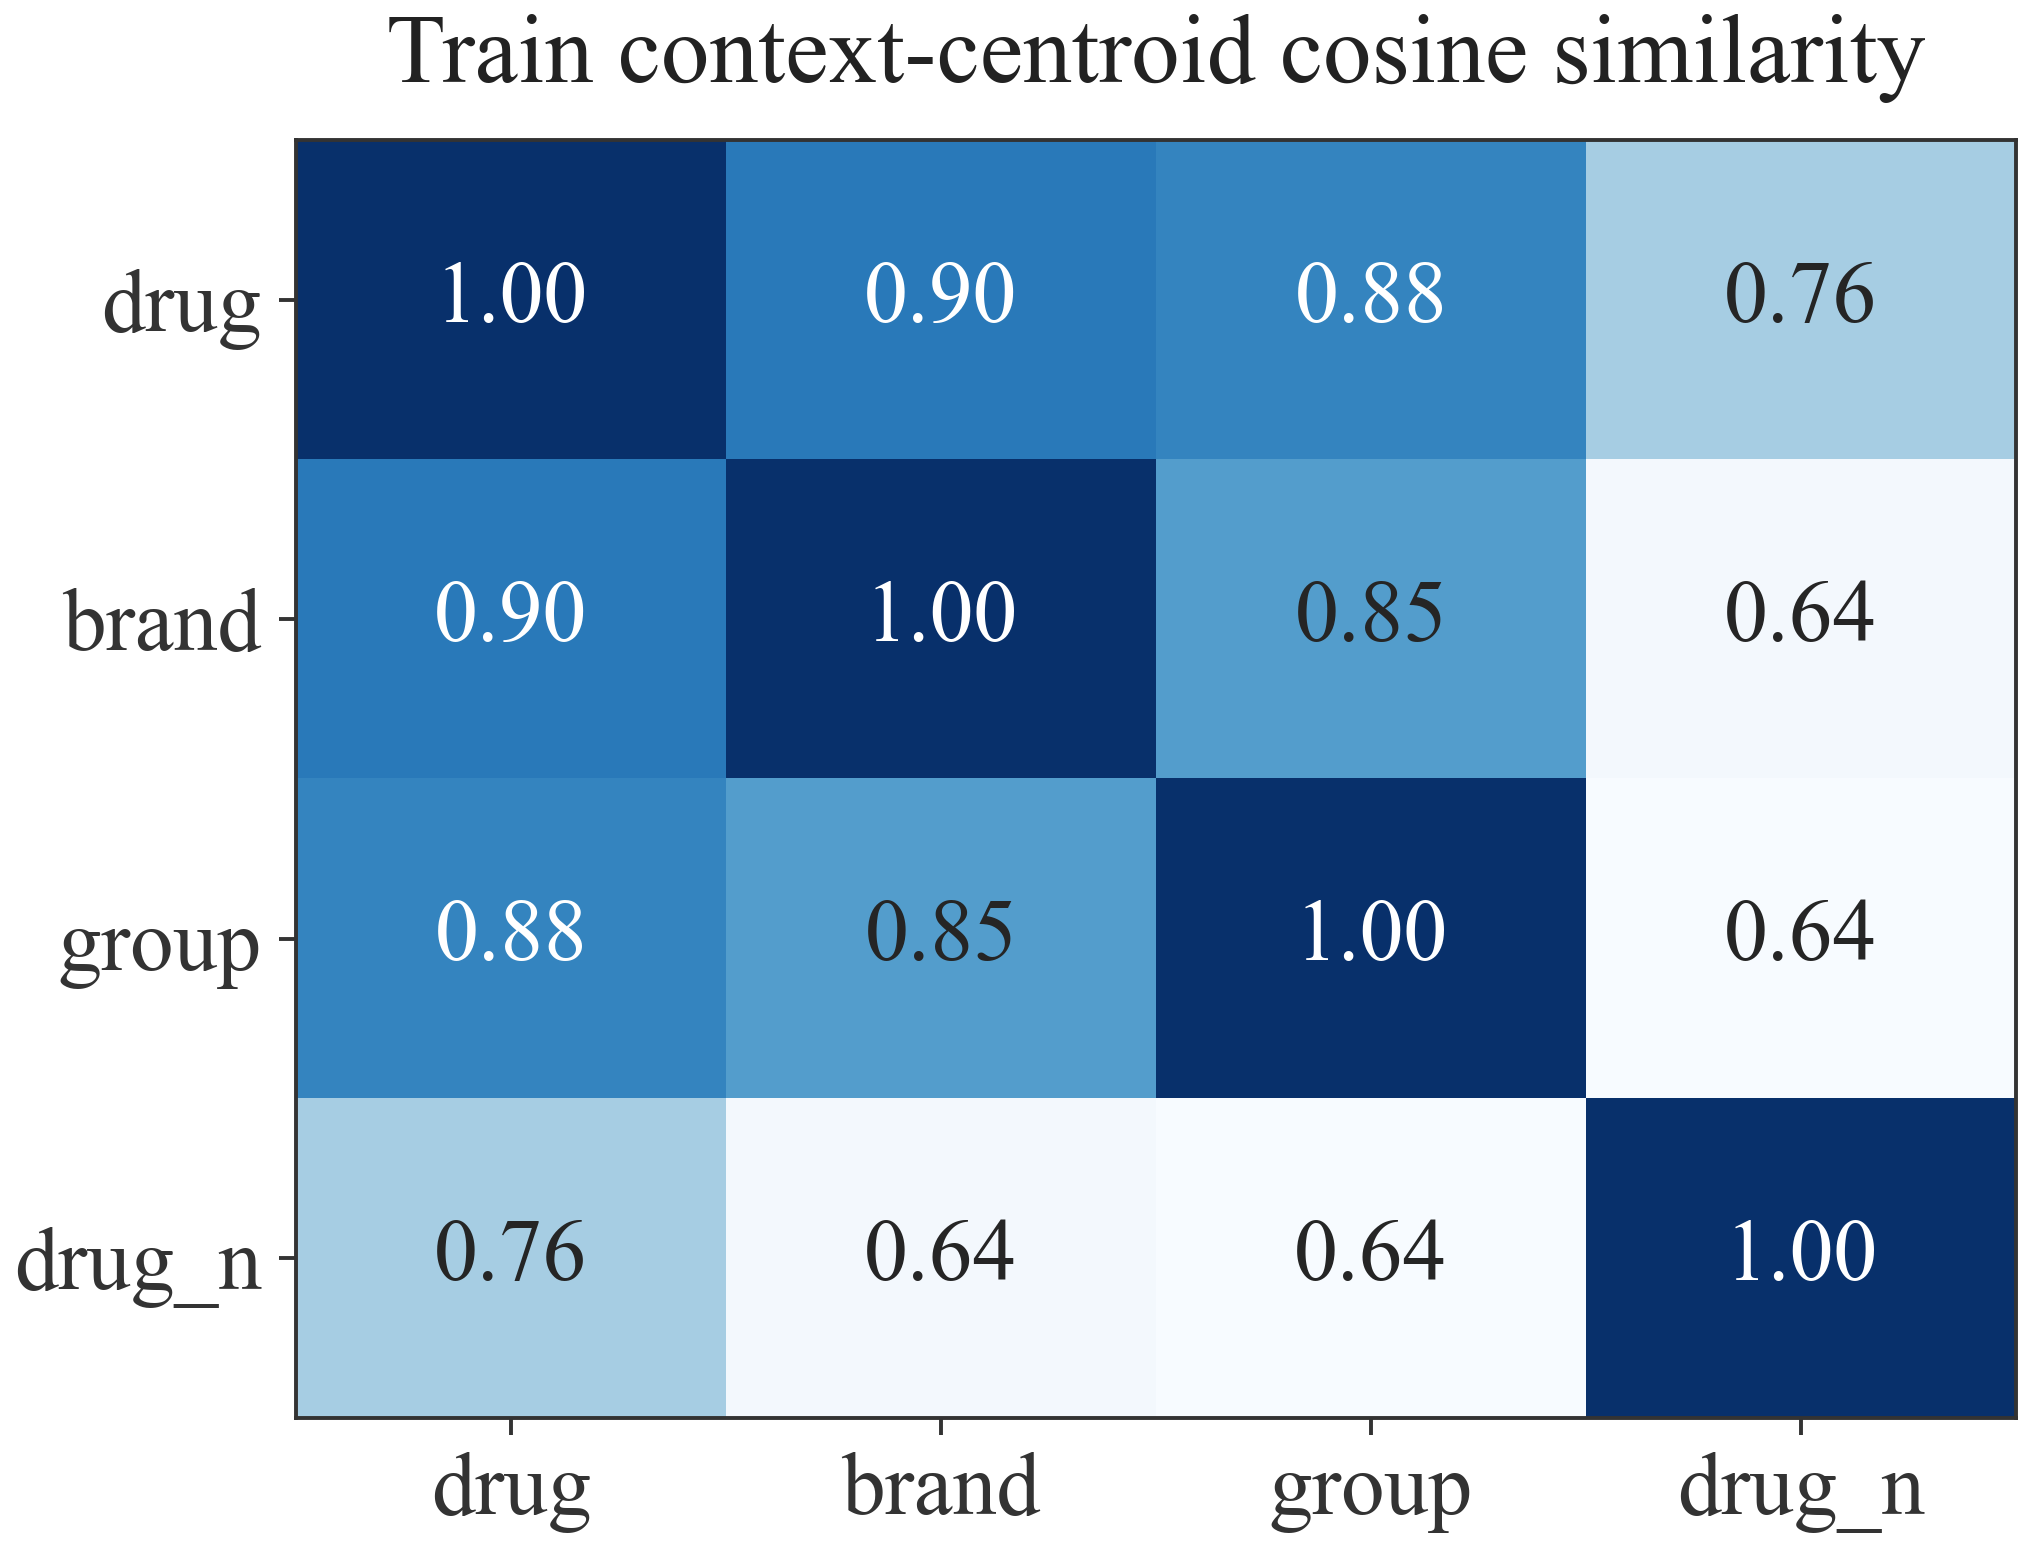

In [41]:
context_similarity = contextual_type_similarity(sentences, gold, window=6)
plot_data = context_similarity.copy()
assert not plot_data.empty
fig, ax = plt.subplots(figsize=(5.8, 4.42), layout="constrained")
fig.get_layout_engine().set(w_pad=0.04, h_pad=0.04, wspace=0.02, hspace=0.02)
matrix = plot_data.pivot(index="Type A", columns="Type B", values="Cosine")
for axis in ("index", "columns"):
    labels = list(getattr(matrix, axis))
    order = (
        list(ENTITY_TYPES) + ["No exact span"]
        if set(ENTITY_TYPES) <= set(labels)
        else ["O", "B", "I", "E", "S"]
    )
    if set(labels) <= set(order):
        matrix = matrix.reindex(**{axis: [label for label in order if label in labels]})
values = matrix.to_numpy(dtype=float)
finite = values[np.isfinite(values)]
assert not np.isinf(values).any()
signed = bool(len(finite) and finite.min() < 0)
colormap = mpl.colormaps["RdBu_r" if signed else "Blues"].copy()
colormap.set_bad("#E4E4E4")
heatmap = ax.imshow(
    np.ma.masked_invalid(values),
    cmap=colormap,
    aspect="auto",
    **{"vmin": -1, "vmax": 1} if signed else {},
)
short_labels = {
    "Overlong": "Too\nlong",
    "Underlong": "Too\nshort",
    "Shifted overlap": "Shifted",
    "Wrong type": "Wrong\ntype",
}
ax.set_xticks(
    range(len(matrix.columns)),
    [short_labels.get(str(v), textwrap.fill(str(v), 11)) for v in matrix.columns],
)
ax.set_yticks(range(len(matrix)), [textwrap.fill(str(v), 16) for v in matrix.index])
for (row, column), value in np.ndenumerate(values):
    rgba = heatmap.cmap(heatmap.norm(value))
    luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
    if not np.isfinite(value):
        annotation = "N/A"
    elif "Cosine" == "Count":
        annotation = f"{value:,.0f}"
    elif 0 < abs(value) < 0.005:
        annotation = ">−0.01" if value < 0 else "<0.01"
    else:
        annotation = f"{value:.2f}".replace("-", "−")
    ax.text(
        column,
        row,
        annotation,
        ha="center",
        va="center",
        fontsize=18,
        color="white" if np.isfinite(value) and luminance < 0.5 else INK,
    )
if np.isnan(values).any():
    assert None
    fig.supxlabel(textwrap.fill(None, 52), fontsize=18, color=INK)
ax.set_title("Train context-centroid cosine similarity", fontsize=20, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
fig.set_dpi(350)
fig.canvas.draw()
for label in fig.findobj(mpl.text.Text):
    if label.get_visible() and label.get_text().strip():
        assert 18 <= label.get_fontsize() <= 20
        label.set_fontfamily("Times New Roman")
fig.savefig(
    PROJECT_ROOT / "figures/PNG/pub_01_context_similarity.png", dpi=350, facecolor="white"
)
fig.savefig(
    PROJECT_ROOT / "figures/PDF/pub_01_context_similarity.pdf", dpi=350, facecolor="white"
)
plot_data.to_csv(
    PROJECT_ROOT / "artifacts/figure_pub_01_context_similarity_data.csv", index=False, na_rep="N/A"
)
plt.show()
plt.close(fig)

The matrix compares TF-IDF centroids of surrounding words with the central entity text excluded.

Six words on each side; four Train-only type centroids; minimum document frequency 3 and at most 10,000 context features.

Similar contexts create plausible typing ambiguity even when entity surface strings differ.

**Scope.** Nearby entity mentions can remain in the window; centroid cosine is neither classification accuracy nor a causal effect.